# Relatório experimental — PINN clássica, PINN-MPC quântica e MPC clássico

**Problema:** equação viscosa de Burgers unidimensional, com solução analítica conhecida.  
**Objetivo:** estudar os hiperparâmetros da PINN clássica, as variantes quânticas do MPC e um controle totalmente clássico com duas MLPs.

> **Como utilizar:** execute as células de cada seção em ordem. As figuras e tabelas já calculadas foram preservadas do notebook original. Se houver novos treinamentos concluídos no cluster, reexecute a célula de carregamento correspondente para atualizar a análise.

## Roteiro de leitura

1. **Problema físico e métricas** — domínio, solução exata e interpretação das perdas.
2. **Seleção da MLP clássica** — profundidade, largura, épocas e learning rate.
3. **PINN-MPC quântica** — qubits, camadas, observáveis e acoplamentos.
4. **Comparação de geradores por produto** — circuito quântico versus segunda MLP clássica.
5. **Comparação final** — MLP, MPC quântica e MPC-MLP-MLP.
6. **Apêndice** — comparação preliminar restrita a MLP versus MPC.

**Nota sobre caminhos:** os experimentos são carregados de `/home/camaral/inct_cq_hybrid_nn/runs/pinn`. Ajuste somente se os diretórios tiverem sido movidos. Os jobs presentes nas células correspondem aos IDs usados no relatório original.

## 1. Problema físico e critérios de avaliação

Considera-se a equação de Burgers viscosa:

$$
\frac{\partial u}{\partial t}+u\frac{\partial u}{\partial x}-\nu\frac{\partial^2u}{\partial x^2}=0,
\qquad (x,t)\in[0,1]^2,\quad\nu=0.05.
$$

A referência analítica utilizada nos experimentos é

$$
u_{\mathrm{ex}}(x,t)=\frac{2\nu a\pi e^{-\nu\pi^2t}\sin(\pi x)}{b+a e^{-\nu\pi^2t}\cos(\pi x)},
\qquad a=0.9,\quad b=1.0.
$$

A condição inicial é $u(x,0)=u_{\mathrm{ex}}(x,0)$, e as condições de contorno são $u(0,t)=u(1,t)=0$.

A função de perda da PINN é a soma de três componentes:

$$
\mathcal{L}=\mathcal{L}_{\mathrm{PDE}}+\mathcal{L}_{\mathrm{IC}}+\mathcal{L}_{\mathrm{BC}}.
$$

Nos arquivos `history.csv`, a coluna `train_mse` representa **essa perda física total**, enquanto `val_mse` representa o erro quadrático médio contra a solução exata, em pontos de validação. O RMSE de teste é calculado sobre uma malha de $250\times250$ pontos.

> **Interpretação dos gráficos:** curvas mostram a média entre as sementes disponíveis; a faixa sombreada indica o mínimo e o máximo, não um intervalo de confiança.

## 2. Ablações da PINN clássica

O modelo de referência é uma MLP com ativação Tanh. As ablações investigam a arquitetura e os hiperparâmetros antes de fixar a configuração final: **4 camadas ocultas, 32 neurônios, 15.000 épocas, Adam com taxa inicial 0,005, scheduler Cosine Annealing e 1.000 pontos de colocação**.

### 2.1. Profundidade da MLP — job 2706

Varia-se o número de camadas ocultas, preservando os demais parâmetros. A seleção considerou quatro camadas ocultas.

### Carregamento e progresso

Carrega históricos, métricas e o resumo por profundidade.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Diretório exclusivo dos experimentos PINN
base = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")

# Job selecionado manualmente
pasta = base / "mlp_depth_2706"

print("Job:", pasta.name)

# Profundidades analisadas
depths = [1, 2, 3, 4, 5]

# Carregar históricos e métricas
historicos = []
metricas = []

for depth in depths:

    modelo = pasta / "results/burgers" / f"pinn_mlp_depth_{depth}"

    for arquivo in sorted(modelo.glob("seed_*/history.csv")):
        seed = int(arquivo.parent.name.split("_")[-1])

        temp = pd.read_csv(arquivo)
        temp["depth"] = depth
        temp["seed"] = seed

        historicos.append(temp)

    for arquivo in sorted(modelo.glob("seed_*/metrics.json")):
        seed = int(arquivo.parent.name.split("_")[-1])

        with open(arquivo) as f:
            m = json.load(f)

        m["depth"] = depth
        m["seed"] = seed

        metricas.append(m)

# DataFrames principais
df = (
    pd.concat(historicos, ignore_index=True)
    if historicos else pd.DataFrame()
)

resultados = pd.DataFrame(metricas)

# Informações gerais
print("Históricos encontrados:", len(historicos))
print("Treinamentos concluídos:", len(resultados), "/ 50")

# Progresso por profundidade
progresso = pd.DataFrame({
    "depth": depths,
    "historicos": [
        sum(h["depth"].iloc[0] == d for h in historicos)
        for d in depths
    ],
    "concluidos": [
        (resultados["depth"] == d).sum()
        if not resultados.empty else 0
        for d in depths
    ]
})

display(progresso)

# Resumo dos resultados disponíveis
if not resultados.empty:

    resumo = (
        resultados.groupby("depth")
        .agg(
            sementes=("seed", "nunique"),
            rmse_medio=("rmse", "mean"),
            rmse_std=("rmse", "std"),
            rmse_min=("rmse", "min"),
            rmse_max=("rmse", "max"),
            parametros=("parameters", "mean")
        )
        .round(6)
    )

    display(resumo)

### Loss total e validação

Analisa a convergência da perda física e do MSE de validação.

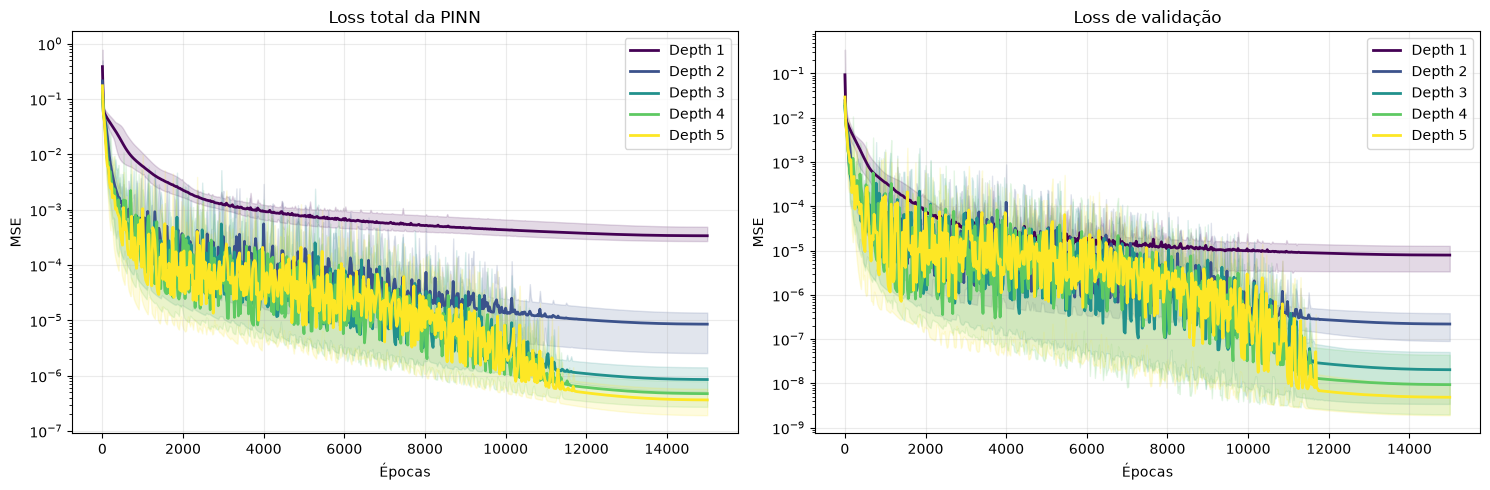

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cores = plt.cm.viridis(np.linspace(0, 1, len(depths)))

for ax, coluna, titulo in zip(
    axes,
    ["train_mse", "val_mse"],
    ["Loss total da PINN", "Loss de validação"]
):

    for depth, cor in zip(depths, cores):

        dados = df[df["depth"] == depth]

        if dados.empty:
            continue

        stats = dados.groupby("epoch")[coluna].agg(
            ["mean", "min", "max"]
        )

        x = stats.index.to_numpy()

        ax.plot(
            x,
            stats["mean"],
            color=cor,
            linewidth=2,
            label=f"Depth {depth}"
        )

        ax.fill_between(
            x,
            stats["min"],
            stats["max"],
            color=cor,
            alpha=0.15
        )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Componentes da loss

Separa o residual da EDP das condições inicial e de contorno.

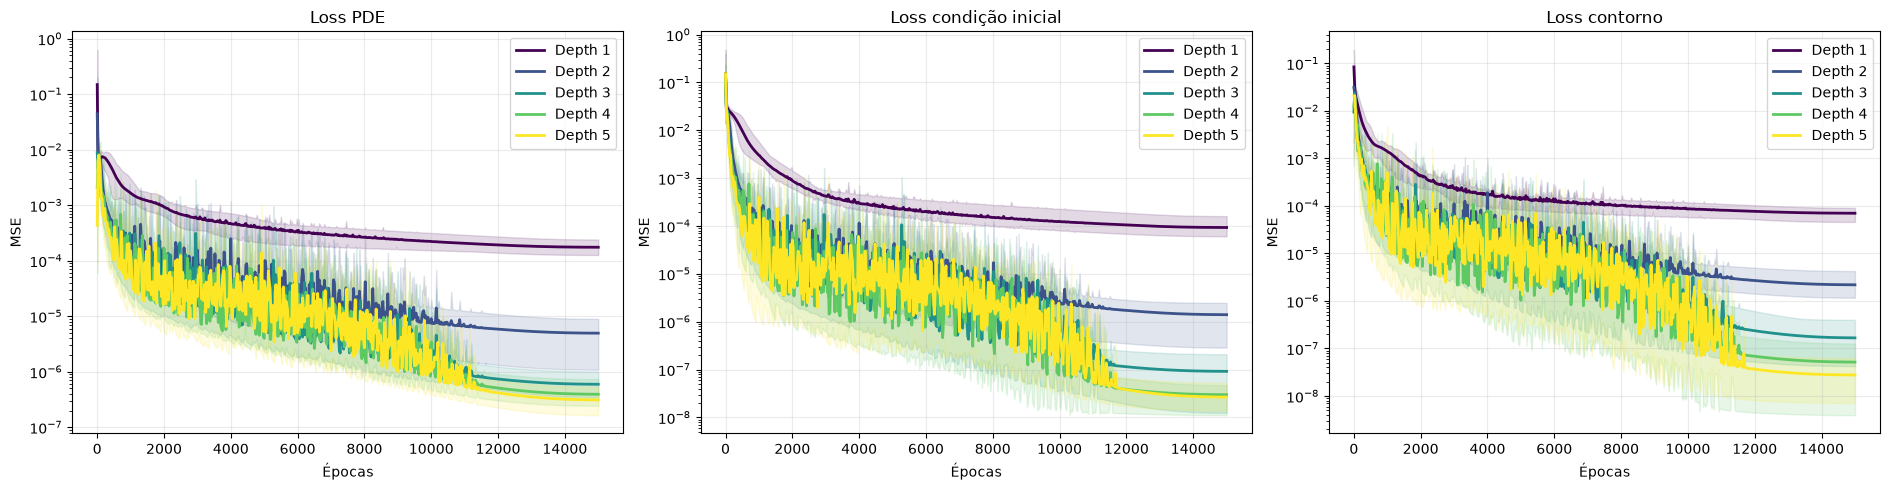

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

componentes = [
    ("loss_pde", "Loss PDE"),
    ("loss_ic", "Loss condição inicial"),
    ("loss_bc", "Loss contorno")
]

cores = plt.cm.viridis(np.linspace(0, 1, len(depths)))

for ax, (coluna, titulo) in zip(axes, componentes):

    for depth, cor in zip(depths, cores):

        dados = df[df["depth"] == depth]

        if dados.empty or coluna not in dados.columns:
            continue

        stats = dados.groupby("epoch")[coluna].agg(
            ["mean", "min", "max"]
        )

        x = stats.index.to_numpy()

        ax.plot(
            x,
            np.maximum(stats["mean"].to_numpy(), 1e-15),
            color=cor,
            linewidth=2,
            label=f"Depth {depth}"
        )

        ax.fill_between(
            x,
            np.maximum(stats["min"].to_numpy(), 1e-15),
            np.maximum(stats["max"].to_numpy(), 1e-15),
            color=cor,
            alpha=0.15
        )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Norma dos gradientes

Investiga a estabilidade dos gradientes da MLP.

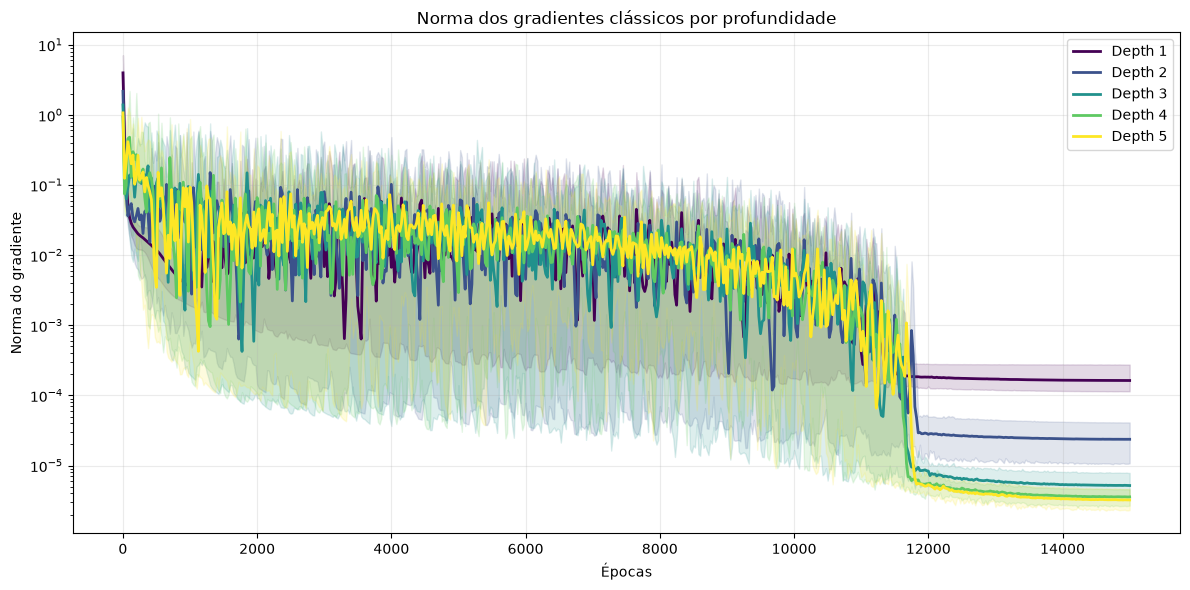

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

cores = plt.cm.viridis(np.linspace(0, 1, len(depths)))

for depth, cor in zip(depths, cores):

    dados = df[df["depth"] == depth]

    if dados.empty:
        continue

    stats = dados.groupby("epoch")["grad_classical"].agg(
        ["mean", "min", "max"]
    )

    x = stats.index.to_numpy()

    ax.plot(
        x,
        np.maximum(stats["mean"].to_numpy(), 1e-15),
        color=cor,
        linewidth=2,
        label=f"Depth {depth}"
    )

    ax.fill_between(
        x,
        np.maximum(stats["min"].to_numpy(), 1e-15),
        np.maximum(stats["max"].to_numpy(), 1e-15),
        color=cor,
        alpha=0.15
    )

ax.set_title("Norma dos gradientes clássicos por profundidade")
ax.set_xlabel("Épocas")
ax.set_ylabel("Norma do gradiente")
ax.grid(alpha=0.25)

if ax.has_data():
    ax.set_yscale("log")
    ax.legend()

plt.tight_layout()
plt.show()

### RMSE médio e amplitude

Compara o erro de teste entre profundidades.

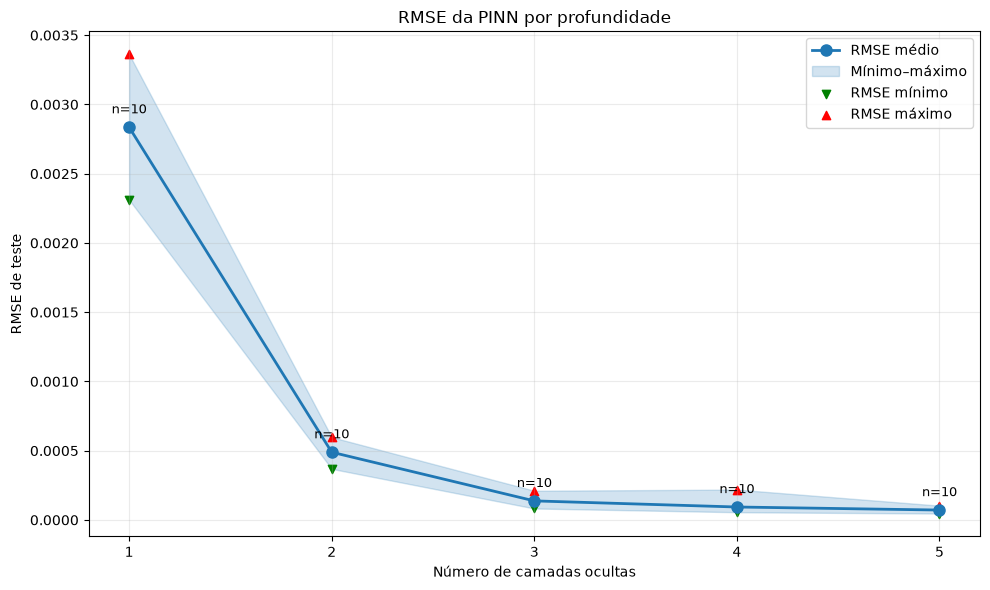

In [ ]:
if not resultados.empty:

    stats = (
        resultados.groupby("depth")["rmse"]
        .agg(["mean", "min", "max", "count"])
        .reindex(depths)
    )

    validos = stats["count"].fillna(0) > 0
    dados = stats.loc[validos]

    fig, ax = plt.subplots(figsize=(10, 6))

    x = dados.index.to_numpy()

    ax.plot(
        x,
        dados["mean"],
        "o-",
        color="tab:blue",
        linewidth=2,
        markersize=8,
        label="RMSE médio"
    )

    ax.fill_between(
        x,
        dados["min"].to_numpy(),
        dados["max"].to_numpy(),
        color="tab:blue",
        alpha=0.2,
        label="Mínimo–máximo"
    )

    ax.scatter(
        x,
        dados["min"],
        marker="v",
        color="green",
        label="RMSE mínimo"
    )

    ax.scatter(
        x,
        dados["max"],
        marker="^",
        color="red",
        label="RMSE máximo"
    )

    ax.set_xticks(depths)
    ax.set_xlabel("Número de camadas ocultas")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("RMSE da PINN por profundidade")
    ax.grid(alpha=0.25)
    ax.legend()

    for depth, linha in dados.iterrows():
        ax.annotate(
            f"n={int(linha['count'])}",
            (depth, linha["mean"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

else:
    print("Ainda não existem treinamentos concluídos.")

### Distribuição do RMSE

Boxplot das sementes disponíveis.

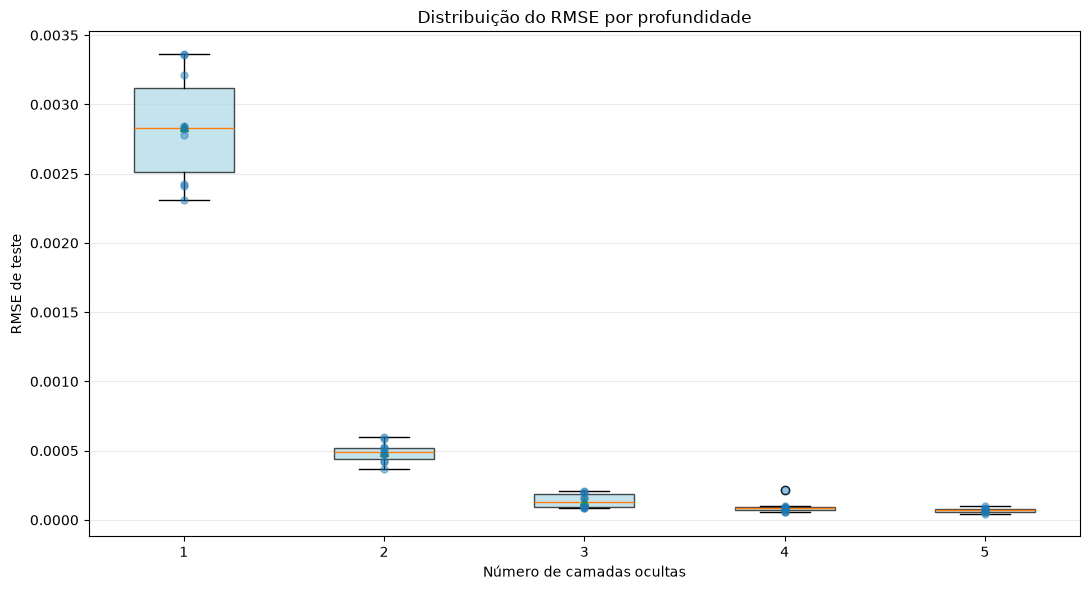

In [ ]:
if not resultados.empty:

    fig, ax = plt.subplots(figsize=(11, 6))

    dados_box = []
    posicoes = []

    for depth in depths:

        valores = resultados.loc[
            resultados["depth"] == depth,
            "rmse"
        ].dropna().to_numpy()

        if len(valores):
            dados_box.append(valores)
            posicoes.append(depth)

    if dados_box:

        bp = ax.boxplot(
            dados_box,
            positions=posicoes,
            widths=0.5,
            patch_artist=True,
            showmeans=True,
            manage_ticks=False
        )

        for patch in bp["boxes"]:
            patch.set_facecolor("lightblue")
            patch.set_alpha(0.7)

        for depth, valores in zip(posicoes, dados_box):
            ax.scatter(
                np.full(len(valores), depth),
                valores,
                color="tab:blue",
                alpha=0.45,
                s=25,
                zorder=3
            )

    ax.set_xticks(depths)
    ax.set_xlabel("Número de camadas ocultas")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("Distribuição do RMSE por profundidade")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

else:
    print("Ainda não existem métricas finais disponíveis.")

### RMSE versus parâmetros

Verifica a relação entre complexidade e precisão.

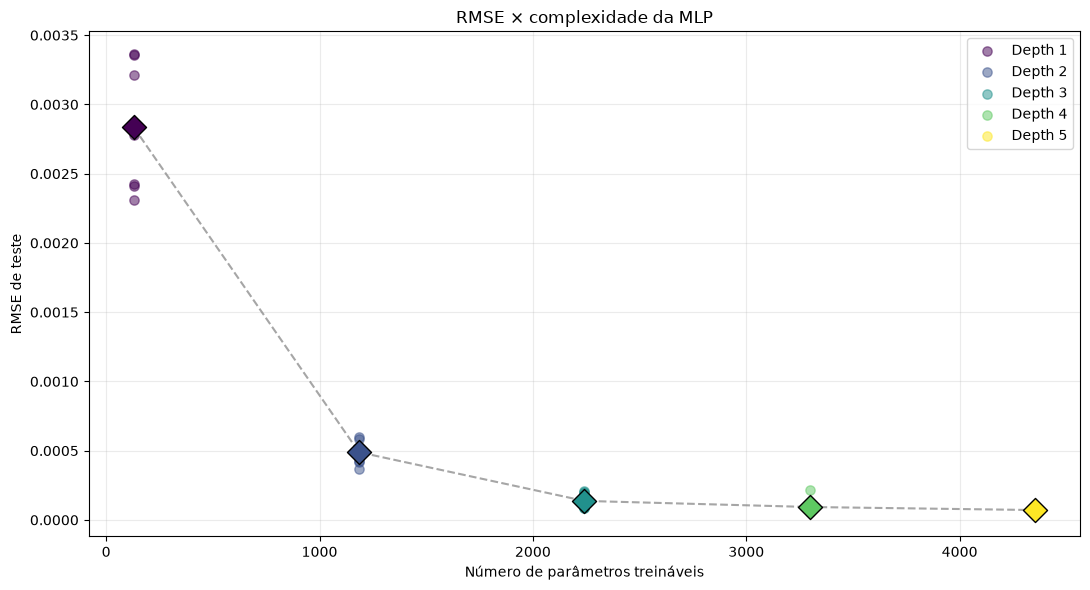

In [ ]:
if not resultados.empty:

    fig, ax = plt.subplots(figsize=(11, 6))

    cores = plt.cm.viridis(np.linspace(0, 1, len(depths)))

    for depth, cor in zip(depths, cores):

        dados = resultados[resultados["depth"] == depth]

        if dados.empty:
            continue

        ax.scatter(
            dados["parameters"],
            dados["rmse"],
            color=cor,
            alpha=0.5,
            s=45,
            label=f"Depth {depth}"
        )

        ax.scatter(
            dados["parameters"].mean(),
            dados["rmse"].mean(),
            color=cor,
            edgecolor="black",
            s=150,
            marker="D",
            zorder=5
        )

    medias = (
        resultados.groupby("depth")
        .agg(
            parametros=("parameters", "mean"),
            rmse=("rmse", "mean")
        )
        .sort_values("parametros")
    )

    ax.plot(
        medias["parametros"],
        medias["rmse"],
        "--",
        color="gray",
        alpha=0.7
    )

    ax.set_xlabel("Número de parâmetros treináveis")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("RMSE × complexidade da MLP")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

else:
    print("Ainda não existem métricas finais disponíveis.")

### Campo analítico, predito e erro

Visualiza a melhor execução disponível e o erro absoluto no domínio.

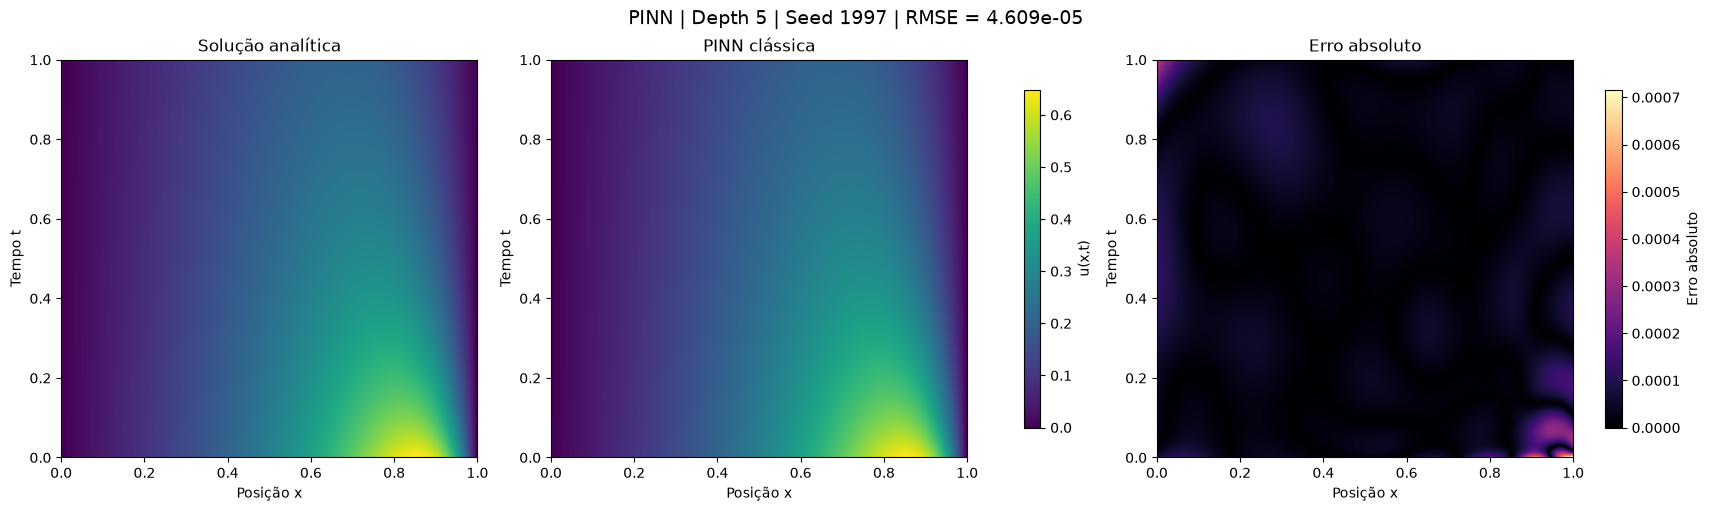

Profundidade: 5
Semente: 1997
Parâmetros: 4353
RMSE: 4.609399e-05


In [ ]:
import sys
import json
import yaml
import torch
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from torch import nn

# ============================================================
# 1. Importar os módulos do projeto
# ============================================================

projeto = Path("/home/camaral/inct_cq_hybrid_nn")
sys.path.insert(0, str(projeto))

from mpc.problems import solution

# Evita importar pinn_mlp_depth.py, que lê config.yaml
# durante a importação e pode causar FileNotFoundError.

with open(projeto / "config.yaml") as f:
    config = yaml.safe_load(f)

problem_cfg = config["problems"]["burgers"]

bounds = torch.tensor(
    problem_cfg["bounds"], dtype=torch.float32
)

# ============================================================
# 2. Reconstruir a arquitetura utilizada no treinamento
# ============================================================

class NormalizeInput(nn.Module):
    def __init__(self, bounds):
        super().__init__()
        self.register_buffer("lo", bounds[:, 0])
        self.register_buffer("hi", bounds[:, 1])

    def forward(self, x):
        return 2 * (x - self.lo) / (self.hi - self.lo) - 1


def make_model(depth, width):
    layers = []
    n = 2

    for _ in range(depth):
        layers.extend([
            nn.Linear(n, width),
            nn.Tanh()
        ])
        n = width

    layers.append(nn.Linear(n, 1))

    return nn.Sequential(*layers)


# ============================================================
# 3. Selecionar o melhor treinamento disponível
# ============================================================

if resultados.empty:
    print("Ainda não existem treinamentos concluídos.")

else:

    melhor = resultados.loc[resultados["rmse"].idxmin()]

    depth = int(melhor["depth"])
    seed = int(melhor["seed"])
    width = int(melhor["width"])

    arquivo = (
        pasta
        / "results/burgers"
        / f"pinn_mlp_depth_{depth}"
        / f"seed_{seed}"
        / "best.pt"
    )

    modelo = nn.Sequential(
        NormalizeInput(bounds),
        make_model(depth, width)
    )

    modelo.load_state_dict(
        torch.load(
            arquivo,
            map_location="cpu",
            weights_only=True
        )
    )

    modelo.eval()

    # ========================================================
    # 4. Calcular solução analítica e previsão
    # ========================================================

    n = 250

    x = np.linspace(0, 1, n)
    t = np.linspace(0, 1, n)

    X, T = np.meshgrid(x, t, indexing="ij")

    coords = torch.tensor(
        np.column_stack([X.ravel(), T.ravel()]),
        dtype=torch.float32
    )

    with torch.no_grad():

        exata = solution(
            "burgers",
            coords,
            problem_cfg
        ).numpy().reshape(n, n)

        prevista = modelo(
            coords
        ).numpy().reshape(n, n)

    erro = np.abs(prevista - exata)

    rmse = np.sqrt(np.mean((prevista - exata)**2))

    # ========================================================
    # 5. Plotar os resultados
    # ========================================================

    vmin = min(exata.min(), prevista.min())
    vmax = max(exata.max(), prevista.max())

    fig, axes = plt.subplots(
        1, 3, figsize=(17, 5),
        constrained_layout=True
    )

    im0 = axes[0].imshow(
        exata.T,
        origin="lower",
        extent=[0, 1, 0, 1],
        aspect="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    im1 = axes[1].imshow(
        prevista.T,
        origin="lower",
        extent=[0, 1, 0, 1],
        aspect="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    im2 = axes[2].imshow(
        erro.T,
        origin="lower",
        extent=[0, 1, 0, 1],
        aspect="auto",
        cmap="magma"
    )

    for ax, titulo in zip(
        axes,
        [
            "Solução analítica",
            "PINN clássica",
            "Erro absoluto"
        ]
    ):
        ax.set_title(titulo)
        ax.set_xlabel("Posição x")
        ax.set_ylabel("Tempo t")

    fig.colorbar(
        im0,
        ax=axes[:2],
        shrink=0.85,
        label="u(x,t)"
    )

    fig.colorbar(
        im2,
        ax=axes[2],
        shrink=0.85,
        label="Erro absoluto"
    )

    fig.suptitle(
        f"PINN | Depth {depth} | Seed {seed} | "
        f"RMSE = {rmse:.3e}",
        fontsize=14
    )

    plt.show()

    print(f"Profundidade: {depth}")
    print(f"Semente: {seed}")
    print(f"Parâmetros: {int(melhor['parameters'])}")
    print(f"RMSE: {rmse:.6e}")

### 2.2. Largura da MLP — job 2708

Profundidade fixada em quatro camadas; compara-se o número de neurônios por camada. A largura selecionada foi 32.

### Carregamento e resumo

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")
pasta_width = base / "mlp_width_2708"

widths = [8, 16, 32, 64, 128]
cores_width = dict(zip(widths, plt.cm.viridis(np.linspace(0, 1, 5))))

historicos = []
metricas = []
progresso = []

for width in widths:

    modelo = (
        pasta_width
        / f"width_{width}"
        / "results/burgers/pinn_mlp_depth_4"
    )

    arquivos_h = sorted(modelo.glob("seed_*/history.csv"))
    arquivos_m = sorted(modelo.glob("seed_*/metrics.json"))

    progresso.append({
        "width": width,
        "historicos": len(arquivos_h),
        "concluidos": len(arquivos_m)
    })

    for arquivo in arquivos_h:
        seed = int(arquivo.parent.name.split("_")[-1])

        temp = pd.read_csv(arquivo)
        temp["width"] = width
        temp["seed"] = seed

        historicos.append(temp)

    for arquivo in arquivos_m:
        seed = int(arquivo.parent.name.split("_")[-1])

        with open(arquivo) as f:
            m = json.load(f)

        m["width"] = width
        m["seed"] = seed
        metricas.append(m)

df_width = (
    pd.concat(historicos, ignore_index=True)
    if historicos else pd.DataFrame()
)

resultados_width = pd.DataFrame(metricas)
progresso_width = pd.DataFrame(progresso)

print("Job:", pasta_width.name)
print("Históricos:", len(historicos))
print("Concluídos:", len(resultados_width), "/50")

display(progresso_width)

if not resultados_width.empty:
    display(
        resultados_width.groupby("width")
        .agg(
            sementes=("seed", "nunique"),
            rmse_medio=("rmse", "mean"),
            rmse_std=("rmse", "std"),
            rmse_min=("rmse", "min"),
            rmse_max=("rmse", "max"),
            parametros=("parameters", "mean")
        )
        .round(6)
    )

Job: mlp_width_2708
Históricos: 50
Concluídos: 50 /50


,width,historicos,concluidos
0,8,10,10
1,16,10,10
2,32,10,10
3,64,10,10
4,128,10,10


,sementes,rmse_medio,rmse_std,rmse_min,rmse_max,parametros
width,,,,,,
8,10,0.000327,0.000072,0.000227,0.000427,249.0
16,10,0.000186,0.000055,0.000101,0.000248,881.0
32,10,0.000093,0.000047,0.000055,0.000219,3297.0
64,10,0.000064,0.000031,0.000033,0.000143,12737.0
128,10,0.000057,0.000025,0.000031,0.000100,50049.0


### Loss total e validação

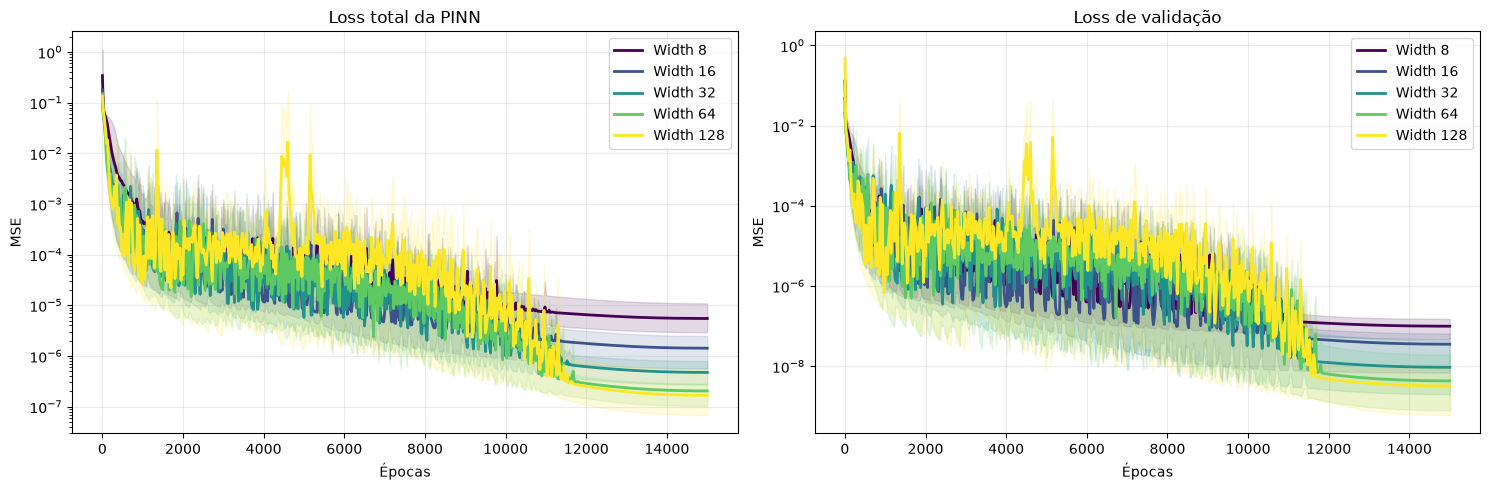

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, coluna, titulo in zip(
    axes,
    ["train_mse", "val_mse"],
    ["Loss total da PINN", "Loss de validação"]
):

    if not df_width.empty:
        for width in widths:

            dados = df_width[df_width["width"] == width]

            if dados.empty:
                continue

            stats = dados.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            x = stats.index.to_numpy()

            ax.plot(
                x,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cores_width[width],
                linewidth=2,
                label=f"Width {width}"
            )

            ax.fill_between(
                x,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cores_width[width],
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Loss PDE, IC e BC

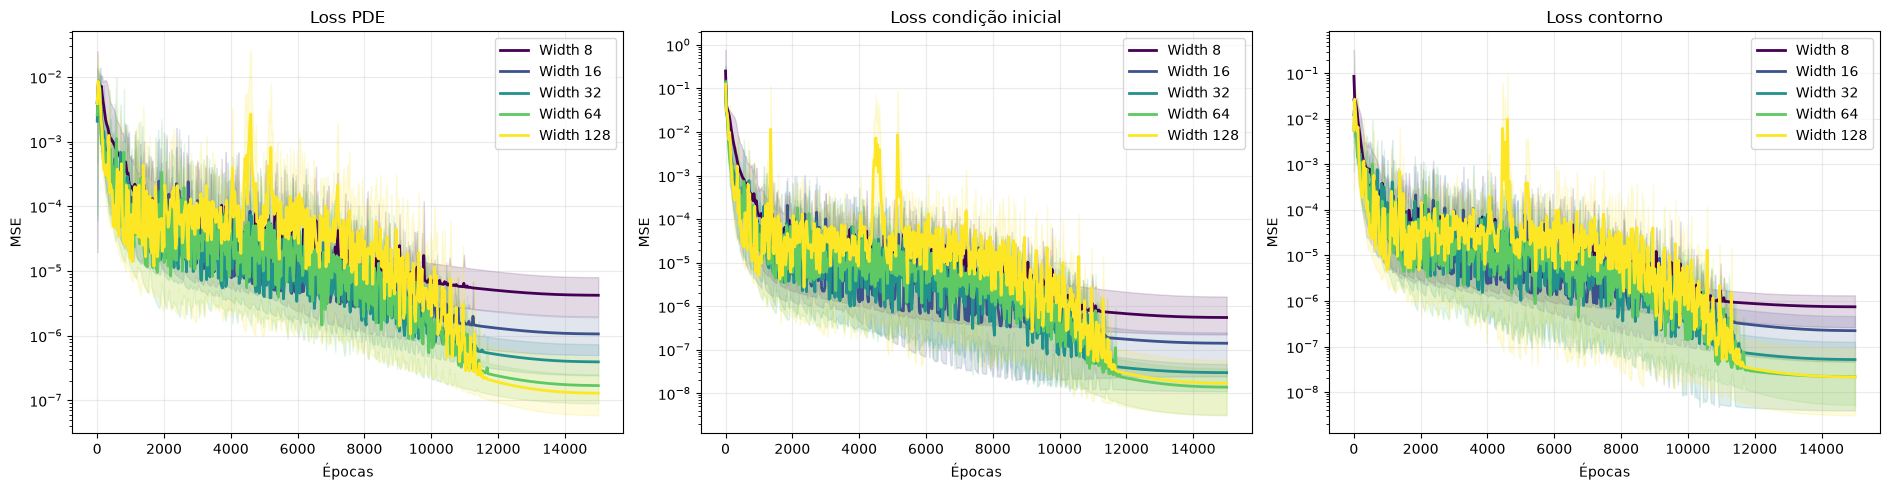

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

componentes = [
    ("loss_pde", "Loss PDE"),
    ("loss_ic", "Loss condição inicial"),
    ("loss_bc", "Loss contorno")
]

for ax, (coluna, titulo) in zip(axes, componentes):

    if not df_width.empty:
        for width in widths:

            dados = df_width[df_width["width"] == width]

            if dados.empty or coluna not in dados.columns:
                continue

            stats = dados.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            x = stats.index.to_numpy()

            ax.plot(
                x,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cores_width[width],
                linewidth=2,
                label=f"Width {width}"
            )

            ax.fill_between(
                x,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cores_width[width],
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Gradientes

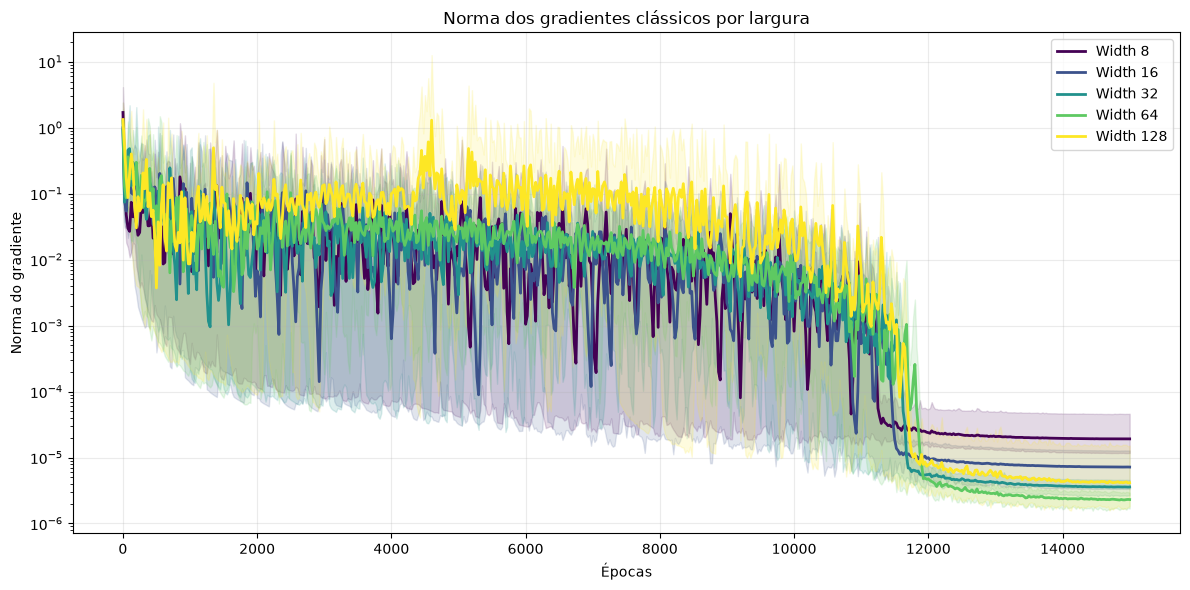

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

if not df_width.empty:

    for width in widths:

        dados = df_width[df_width["width"] == width]

        if dados.empty:
            continue

        stats = dados.groupby("epoch")["grad_classical"].agg(
            ["mean", "min", "max"]
        )

        x = stats.index.to_numpy()

        ax.plot(
            x,
            np.maximum(stats["mean"].to_numpy(), 1e-15),
            color=cores_width[width],
            linewidth=2,
            label=f"Width {width}"
        )

        ax.fill_between(
            x,
            np.maximum(stats["min"].to_numpy(), 1e-15),
            np.maximum(stats["max"].to_numpy(), 1e-15),
            color=cores_width[width],
            alpha=0.15
        )

ax.set_title("Norma dos gradientes clássicos por largura")
ax.set_xlabel("Épocas")
ax.set_ylabel("Norma do gradiente")
ax.grid(alpha=0.25)

if ax.has_data():
    ax.set_yscale("log")
    ax.legend()

plt.tight_layout()
plt.show()

### RMSE médio e amplitude

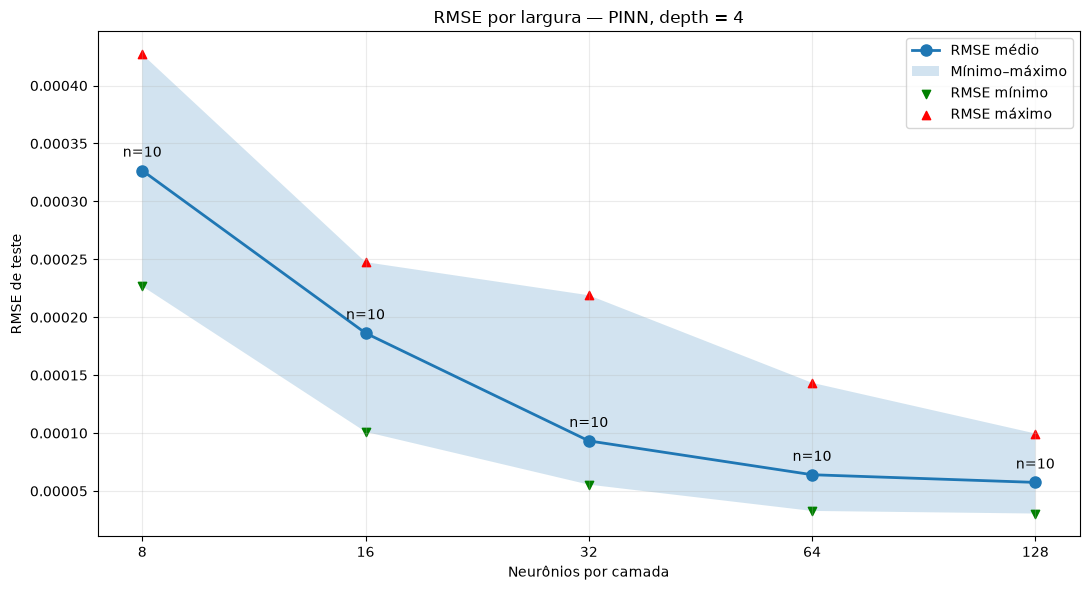

In [ ]:
if not resultados_width.empty:

    stats = (
        resultados_width.groupby("width")["rmse"]
        .agg(["mean", "min", "max", "count"])
        .reindex(widths)
        .dropna(subset=["mean"])
    )

    x = np.arange(len(stats))

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.plot(
        x, stats["mean"],
        "o-", linewidth=2, markersize=8,
        label="RMSE médio"
    )

    ax.fill_between(
        x,
        stats["min"].to_numpy(),
        stats["max"].to_numpy(),
        alpha=0.2,
        label="Mínimo–máximo"
    )

    ax.scatter(
        x, stats["min"],
        marker="v", color="green",
        label="RMSE mínimo"
    )

    ax.scatter(
        x, stats["max"],
        marker="^", color="red",
        label="RMSE máximo"
    )

    for i, (_, linha) in enumerate(stats.iterrows()):
        ax.annotate(
            f"n={int(linha['count'])}",
            (i, linha["mean"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

    ax.set_xticks(x)
    ax.set_xticklabels(stats.index)
    ax.set_xlabel("Neurônios por camada")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("RMSE por largura — PINN, depth = 4")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

else:
    print("Ainda não existem treinamentos concluídos.")

### Boxplot do RMSE

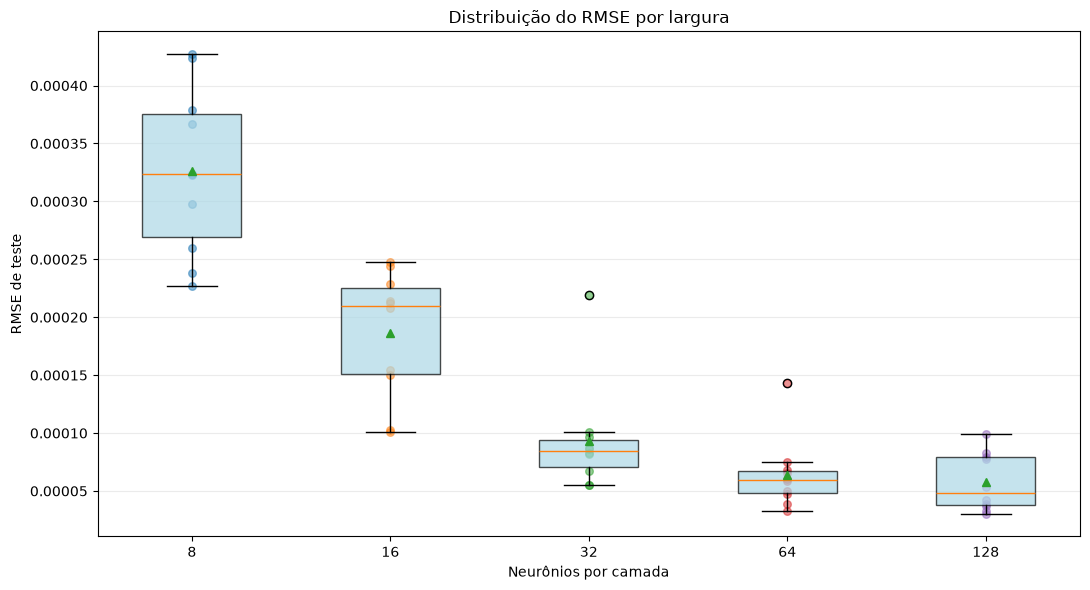

In [ ]:
if not resultados_width.empty:

    fig, ax = plt.subplots(figsize=(11, 6))

    dados_box = []
    posicoes = []

    for i, width in enumerate(widths):

        valores = resultados_width.loc[
            resultados_width["width"] == width,
            "rmse"
        ].dropna().to_numpy()

        if len(valores):
            dados_box.append(valores)
            posicoes.append(i)

    if dados_box:

        bp = ax.boxplot(
            dados_box,
            positions=posicoes,
            widths=0.5,
            patch_artist=True,
            showmeans=True,
            manage_ticks=False
        )

        for patch in bp["boxes"]:
            patch.set_facecolor("lightblue")
            patch.set_alpha(0.7)

        for pos, valores in zip(posicoes, dados_box):
            ax.scatter(
                np.full(len(valores), pos),
                valores,
                alpha=0.5,
                s=30
            )

    ax.set_xticks(range(len(widths)))
    ax.set_xticklabels(widths)
    ax.set_xlabel("Neurônios por camada")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("Distribuição do RMSE por largura")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

### RMSE versus parâmetros

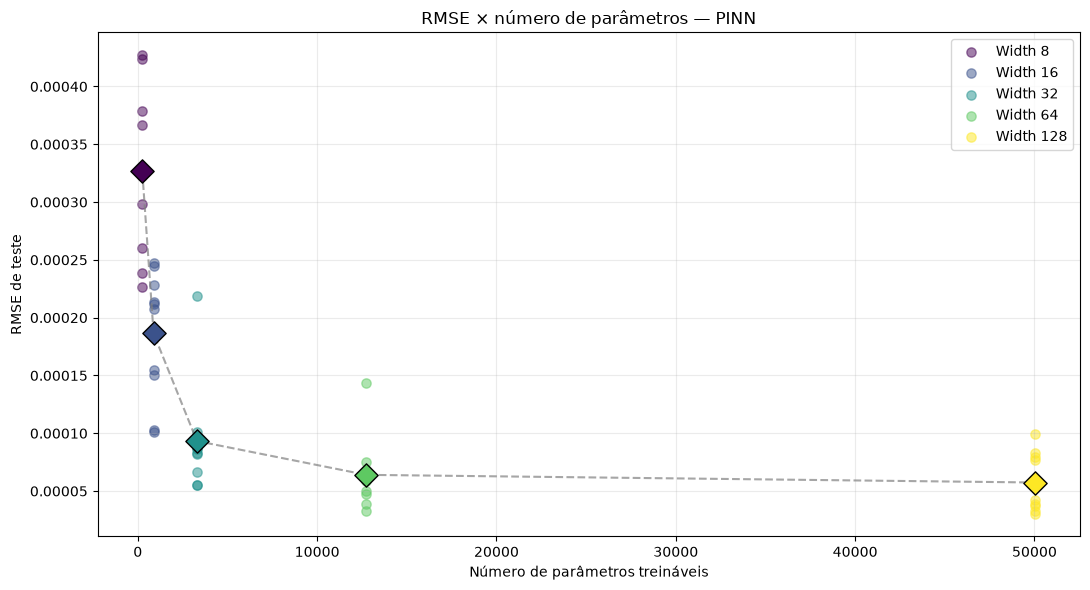

In [ ]:
if not resultados_width.empty:

    fig, ax = plt.subplots(figsize=(11, 6))

    for width in widths:

        dados = resultados_width[
            resultados_width["width"] == width
        ]

        if dados.empty:
            continue

        ax.scatter(
            dados["parameters"],
            dados["rmse"],
            color=cores_width[width],
            alpha=0.5,
            s=45,
            label=f"Width {width}"
        )

        ax.scatter(
            dados["parameters"].mean(),
            dados["rmse"].mean(),
            color=cores_width[width],
            edgecolor="black",
            marker="D",
            s=140,
            zorder=5
        )

    medias = (
        resultados_width.groupby("width")
        .agg(
            parametros=("parameters", "mean"),
            rmse=("rmse", "mean")
        )
        .sort_values("parametros")
    )

    ax.plot(
        medias["parametros"],
        medias["rmse"],
        "--", color="gray", alpha=0.7
    )

    ax.set_xlabel("Número de parâmetros treináveis")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("RMSE × número de parâmetros — PINN")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

### 2.3. Número de épocas — job 2757

Com a arquitetura principal fixada, compara-se a duração do treinamento. O valor escolhido para a sequência de experimentos foi **15.000 épocas**.

**Observação:** a célula de carregamento abaixo é genérica e permite trocar `etapa` entre `epochs`, `lr`, `scheduler` e `points`; neste relatório está configurada para a ablação de épocas.

### Carregamento e progresso

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")

# ============================================================
# Selecionar experimento
# ============================================================

etapa = "epochs"  # "epochs", "lr", "scheduler", "points"
job_id = "2757"      # Substituir pelo ID retornado pelo qsub

configuracoes = {
    "epochs": ["2500", "5000", "10000", "15000", "20000"],
    "lr": ["0.0001", "0.0005", "0.001", "0.005", "0.01"],
    "scheduler": ["none", "cosine", "step"],
    "points": ["250", "500", "1000", "2000", "4000"]
}

valores = configuracoes[etapa]
pasta_ablacao = base / f"mlp_{etapa}_{job_id}"

historicos = []
metricas = []
progresso = []

for valor in valores:

    modelo = (
        pasta_ablacao
        / f"{etapa}_{valor}"
        / "results/burgers/pinn_mlp_depth_4"
    )

    arquivos_h = sorted(modelo.glob("seed_*/history.csv"))
    arquivos_m = sorted(modelo.glob("seed_*/metrics.json"))

    progresso.append({
        "configuracao": valor,
        "historicos": len(arquivos_h),
        "concluidos": len(arquivos_m)
    })

    for arquivo in arquivos_h:
        seed = int(arquivo.parent.name.split("_")[-1])

        temp = pd.read_csv(arquivo)
        temp["configuracao"] = valor
        temp["seed"] = seed

        historicos.append(temp)

    for arquivo in arquivos_m:
        seed = int(arquivo.parent.name.split("_")[-1])

        with open(arquivo) as f:
            m = json.load(f)

        m["configuracao"] = valor
        m["seed"] = seed

        metricas.append(m)

df_ab = (
    pd.concat(historicos, ignore_index=True)
    if historicos else pd.DataFrame()
)

resultados_ab = pd.DataFrame(metricas)
progresso_ab = pd.DataFrame(progresso)

print("Experimento:", etapa)
print("Job:", job_id)
print("Históricos:", len(historicos))
print("Concluídos:", len(metricas), "/", len(valores) * 10)

display(progresso_ab)

if not resultados_ab.empty:
    display(
        resultados_ab.groupby("configuracao")
        .agg(
            sementes=("seed", "nunique"),
            rmse_medio=("rmse", "mean"),
            rmse_std=("rmse", "std"),
            rmse_min=("rmse", "min"),
            rmse_max=("rmse", "max")
        )
        .reindex(valores)
        .round(6)
    )

Experimento: epochs
Job: 2757
Históricos: 50
Concluídos: 50 / 50


,configuracao,historicos,concluidos
0,2500,10,10
1,5000,10,10
2,10000,10,10
3,15000,10,10
4,20000,10,10


,sementes,rmse_medio,rmse_std,rmse_min,rmse_max
configuracao,,,,,
2500,10,0.000844,0.000222,0.000491,0.001173
5000,10,0.000433,0.000100,0.000293,0.000575
10000,10,0.000154,0.000075,0.000086,0.000351
15000,10,0.000093,0.000047,0.000055,0.000219
20000,10,0.000076,0.000038,0.000036,0.000174


### Loss total e validação

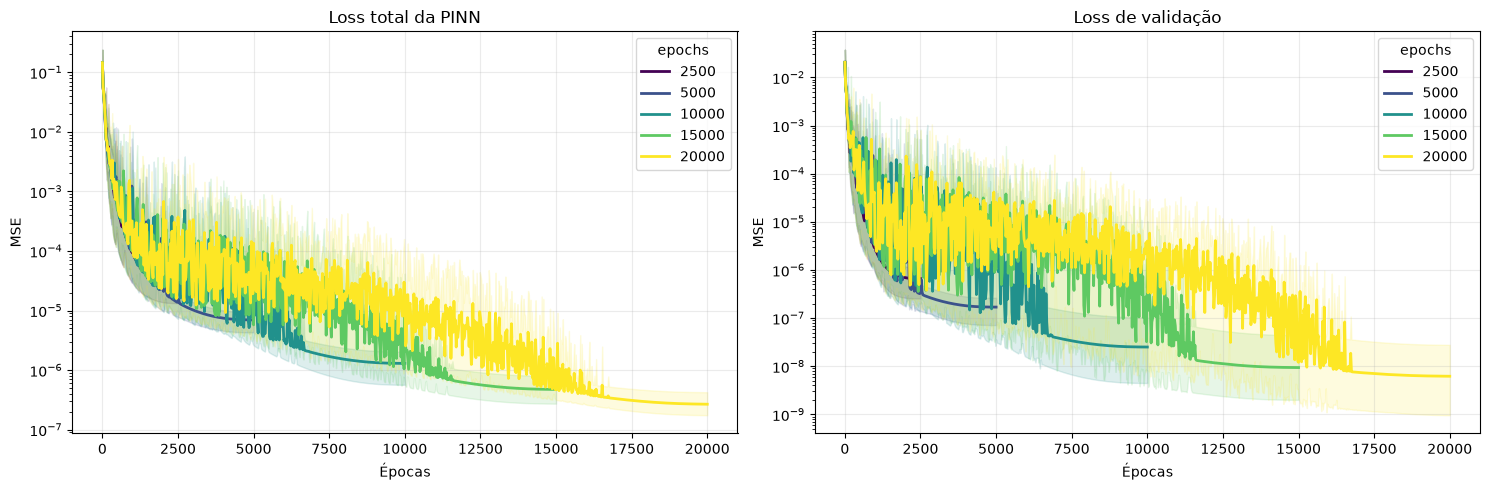

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cores = dict(zip(
    valores,
    plt.cm.viridis(np.linspace(0, 1, len(valores)))
))

for ax, coluna, titulo in zip(
    axes,
    ["train_mse", "val_mse"],
    ["Loss total da PINN", "Loss de validação"]
):

    if not df_ab.empty:

        for valor in valores:

            dados = df_ab[df_ab["configuracao"] == valor]

            if dados.empty:
                continue

            stats = dados.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            x = stats.index.to_numpy()

            ax.plot(
                x,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cores[valor],
                linewidth=2,
                label=valor
            )

            ax.fill_between(
                x,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cores[valor],
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend(title=etapa)

plt.tight_layout()
plt.show()

### Componentes da loss

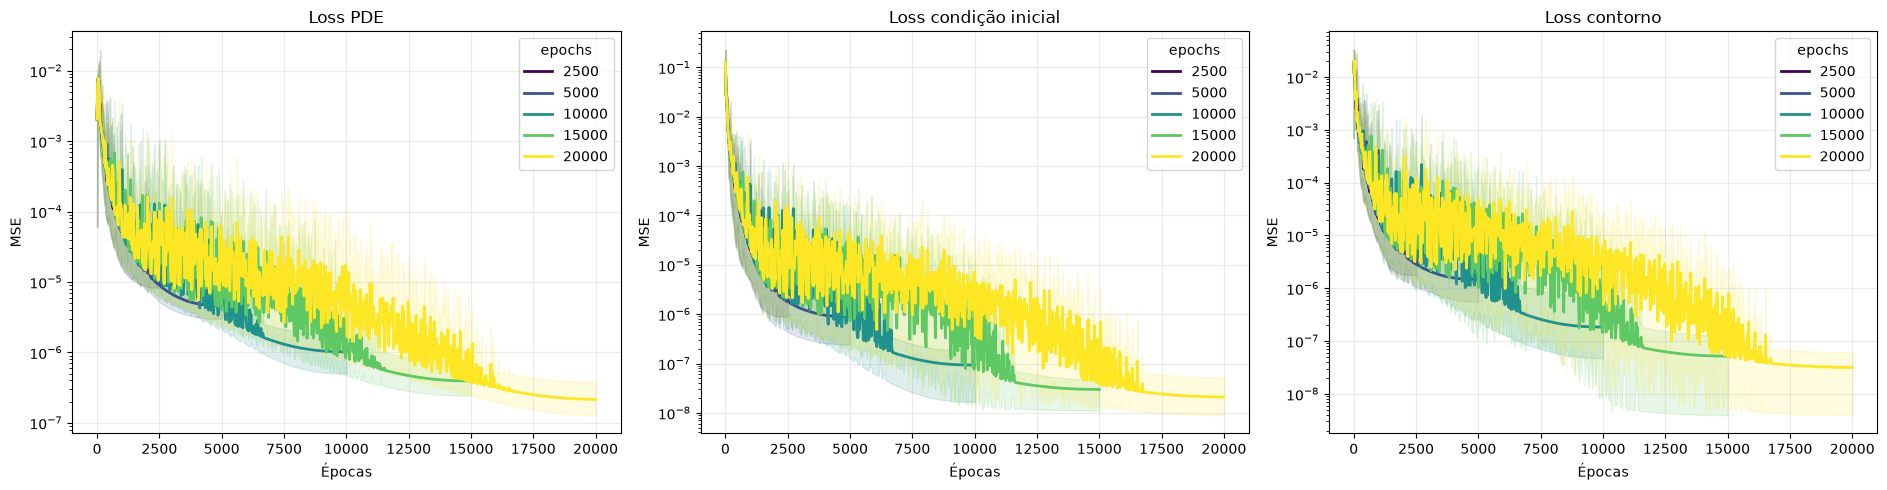

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

componentes = [
    ("loss_pde", "Loss PDE"),
    ("loss_ic", "Loss condição inicial"),
    ("loss_bc", "Loss contorno")
]

for ax, (coluna, titulo) in zip(axes, componentes):

    if not df_ab.empty:

        for valor in valores:

            dados = df_ab[df_ab["configuracao"] == valor]

            if dados.empty:
                continue

            stats = dados.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            ax.plot(
                stats.index,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cores[valor],
                linewidth=2,
                label=valor
            )

            ax.fill_between(
                stats.index,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cores[valor],
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend(title=etapa)

plt.tight_layout()
plt.show()

### Gradientes

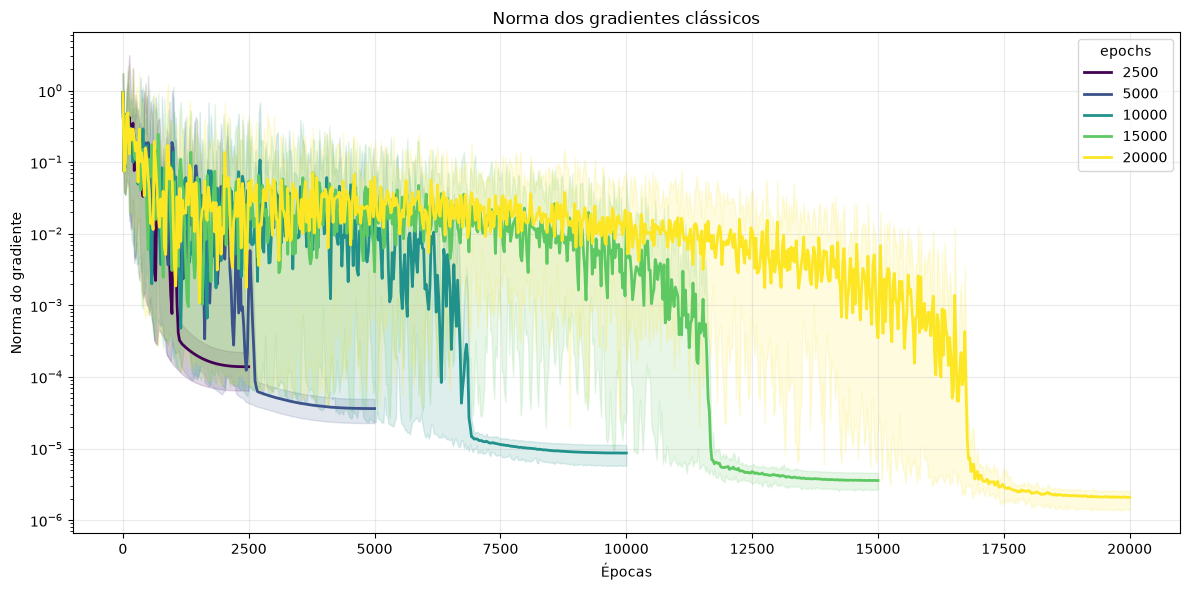

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

if not df_ab.empty:

    for valor in valores:

        dados = df_ab[df_ab["configuracao"] == valor]

        if dados.empty:
            continue

        stats = dados.groupby("epoch")["grad_classical"].agg(
            ["mean", "min", "max"]
        )

        ax.plot(
            stats.index,
            np.maximum(stats["mean"].to_numpy(), 1e-15),
            color=cores[valor],
            linewidth=2,
            label=valor
        )

        ax.fill_between(
            stats.index,
            np.maximum(stats["min"].to_numpy(), 1e-15),
            np.maximum(stats["max"].to_numpy(), 1e-15),
            color=cores[valor],
            alpha=0.15
        )

ax.set_title("Norma dos gradientes clássicos")
ax.set_xlabel("Épocas")
ax.set_ylabel("Norma do gradiente")
ax.grid(alpha=0.25)

if ax.has_data():
    ax.set_yscale("log")
    ax.legend(title=etapa)

plt.tight_layout()
plt.show()

### RMSE médio e amplitude

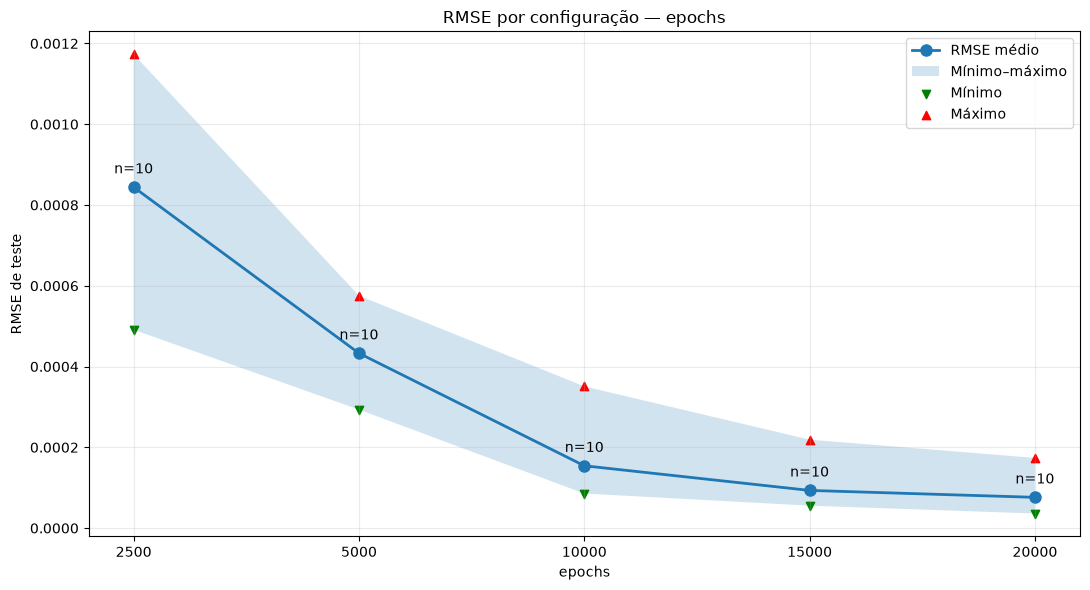

In [ ]:
if not resultados_ab.empty:

    stats = (
        resultados_ab.groupby("configuracao")["rmse"]
        .agg(["mean", "min", "max", "count"])
        .reindex(valores)
        .dropna(subset=["mean"])
    )

    x = np.arange(len(stats))

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.plot(
        x,
        stats["mean"].to_numpy(),
        "o-",
        linewidth=2,
        markersize=8,
        label="RMSE médio"
    )

    ax.fill_between(
        x,
        stats["min"].to_numpy(),
        stats["max"].to_numpy(),
        alpha=0.2,
        label="Mínimo–máximo"
    )

    ax.scatter(
        x,
        stats["min"],
        color="green",
        marker="v",
        label="Mínimo"
    )

    ax.scatter(
        x,
        stats["max"],
        color="red",
        marker="^",
        label="Máximo"
    )

    for i, (_, linha) in enumerate(stats.iterrows()):
        ax.annotate(
            f"n={int(linha['count'])}",
            (i, linha["mean"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

    ax.set_xticks(x)
    ax.set_xticklabels(stats.index)
    ax.set_xlabel(etapa)
    ax.set_ylabel("RMSE de teste")
    ax.set_title(f"RMSE por configuração — {etapa}")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

else:
    print("Ainda não existem métricas finais.")

### Boxplot do RMSE

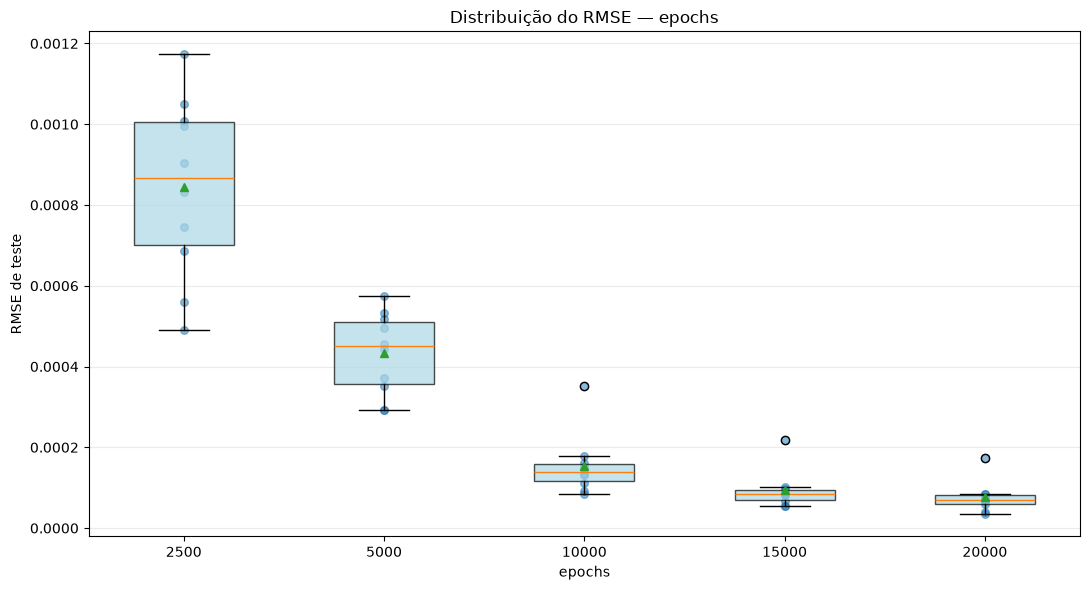

In [ ]:
if not resultados_ab.empty:

    grupos = [
        resultados_ab.loc[
            resultados_ab["configuracao"] == valor,
            "rmse"
        ].dropna().to_numpy()
        for valor in valores
    ]

    posicoes = [
        i for i, grupo in enumerate(grupos) if len(grupo)
    ]

    dados_box = [grupos[i] for i in posicoes]

    fig, ax = plt.subplots(figsize=(11, 6))

    if dados_box:

        bp = ax.boxplot(
            dados_box,
            positions=posicoes,
            widths=0.5,
            patch_artist=True,
            showmeans=True,
            manage_ticks=False
        )

        for patch in bp["boxes"]:
            patch.set_facecolor("lightblue")
            patch.set_alpha(0.7)

        for pos, grupo in zip(posicoes, dados_box):
            ax.scatter(
                np.full(len(grupo), pos),
                grupo,
                alpha=0.5,
                s=30,
                color="tab:blue"
            )

    ax.set_xticks(range(len(valores)))
    ax.set_xticklabels(valores)
    ax.set_xlabel(etapa)
    ax.set_ylabel("RMSE de teste")
    ax.set_title(f"Distribuição do RMSE — {etapa}")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

### RMSE por semente

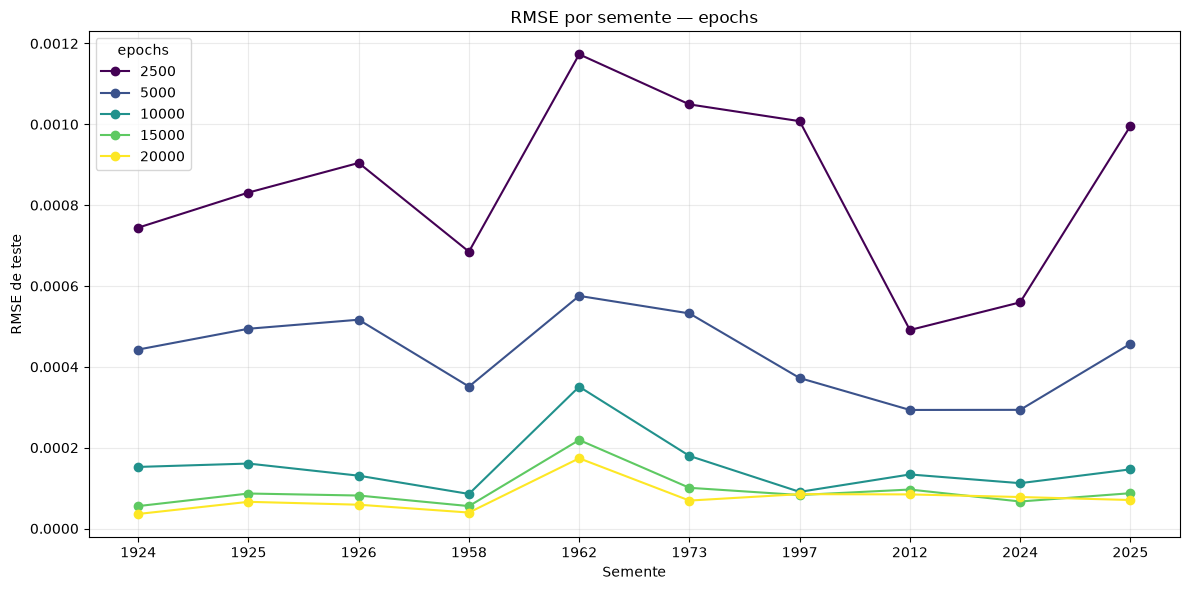

In [ ]:
if not resultados_ab.empty:

    fig, ax = plt.subplots(figsize=(12, 6))

    for valor in valores:

        dados = (
            resultados_ab[
                resultados_ab["configuracao"] == valor
            ]
            .sort_values("seed")
        )

        if dados.empty:
            continue

        ax.plot(
            dados["seed"].astype(str),
            dados["rmse"],
            "o-",
            color=cores[valor],
            linewidth=1.5,
            label=valor
        )

    ax.set_xlabel("Semente")
    ax.set_ylabel("RMSE de teste")
    ax.set_title(f"RMSE por semente — {etapa}")
    ax.grid(alpha=0.25)
    ax.legend(title=etapa)

    plt.tight_layout()
    plt.show()

### Tabela consolidada

In [ ]:
if not resultados_ab.empty:

    resumo_ab = (
        resultados_ab.groupby("configuracao")
        .agg(
            sementes=("seed", "nunique"),
            rmse_medio=("rmse", "mean"),
            rmse_std=("rmse", "std"),
            rmse_min=("rmse", "min"),
            rmse_max=("rmse", "max"),
            mae_medio=("mae", "mean"),
            l2_relativo=("relative_l2", "mean"),
            parametros=("parameters", "mean"),
            melhor_epoca=("best_epoch", "mean")
        )
        .reindex(valores)
        .round(6)
    )

    display(resumo_ab)

else:
    print("Ainda não existem resultados para a tabela.")

,sementes,rmse_medio,rmse_std,rmse_min,rmse_max,mae_medio,l2_relativo,parametros,melhor_epoca
configuracao,,,,,,,,,
2500,10,0.000844,0.000222,0.000491,0.001173,0.000520,0.003813,3297.0,2500.0
5000,10,0.000433,0.000100,0.000293,0.000575,0.000274,0.001955,3297.0,4992.5
10000,10,0.000154,0.000075,0.000086,0.000351,0.000091,0.000697,3297.0,10000.0
15000,10,0.000093,0.000047,0.000055,0.000219,0.000053,0.000421,3297.0,15000.0
20000,10,0.000076,0.000038,0.000036,0.000174,0.000040,0.000344,3297.0,19140.0


### 2.4. Taxa de aprendizado — job 2767

Testes com taxas iniciais de aprendizado distintas, mantendo **15.000 épocas**. A opção selecionada foi **$5	imes10^{-3}$**.

### Carregamento e progresso

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

job_id = "2767"  # Substituir pelo ID real

pasta = (
    Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")
    / f"mlp_lr_{job_id}"
)

lrs = ["0.0001", "0.0005", "0.001", "0.005", "0.01"]
cores = dict(zip(lrs, plt.cm.viridis(np.linspace(0, 1, len(lrs)))))

historicos = []
metricas = []
progresso = []

for lr in lrs:

    modelo = (
        pasta
        / f"lr_{lr}"
        / "results/burgers/pinn_mlp_depth_4"
    )

    arquivos_h = sorted(modelo.glob("seed_*/history.csv"))
    arquivos_m = sorted(modelo.glob("seed_*/metrics.json"))

    progresso.append({
        "lr": lr,
        "historicos": len(arquivos_h),
        "concluidos": len(arquivos_m)
    })

    for arquivo in arquivos_h:
        seed = int(arquivo.parent.name.split("_")[-1])

        temp = pd.read_csv(arquivo)
        temp["lr_config"] = lr
        temp["seed"] = seed
        historicos.append(temp)

    for arquivo in arquivos_m:
        seed = int(arquivo.parent.name.split("_")[-1])

        with open(arquivo) as f:
            m = json.load(f)

        m["lr_config"] = lr
        m["seed"] = seed
        metricas.append(m)

df_lr = (
    pd.concat(historicos, ignore_index=True)
    if historicos else pd.DataFrame()
)

resultados_lr = pd.DataFrame(metricas)

print("Pasta:", pasta)
print("Históricos encontrados:", len(historicos))
print("Treinamentos concluídos:", len(metricas), "/50")

display(pd.DataFrame(progresso))

if not resultados_lr.empty:
    display(
        resultados_lr.groupby("lr_config")
        .agg(
            sementes=("seed", "nunique"),
            rmse_medio=("rmse", "mean"),
            rmse_std=("rmse", "std"),
            rmse_min=("rmse", "min"),
            rmse_max=("rmse", "max")
        )
        .reindex(lrs)
        .round(6)
    )

Pasta: /home/camaral/inct_cq_hybrid_nn/runs/pinn/mlp_lr_2767
Históricos encontrados: 50
Treinamentos concluídos: 50 /50


,lr,historicos,concluidos
0,0.0001,10,10
1,0.0005,10,10
2,0.001,10,10
3,0.005,10,10
4,0.01,10,10


,sementes,rmse_medio,rmse_std,rmse_min,rmse_max
lr_config,,,,,
0.0001,10,0.000887,0.000512,0.000440,0.002161
0.0005,10,0.000646,0.000382,0.000300,0.001610
0.001,10,0.000490,0.000401,0.000229,0.001575
0.005,10,0.000093,0.000047,0.000055,0.000219
0.01,10,0.000067,0.000011,0.000053,0.000083


### Loss total e validação

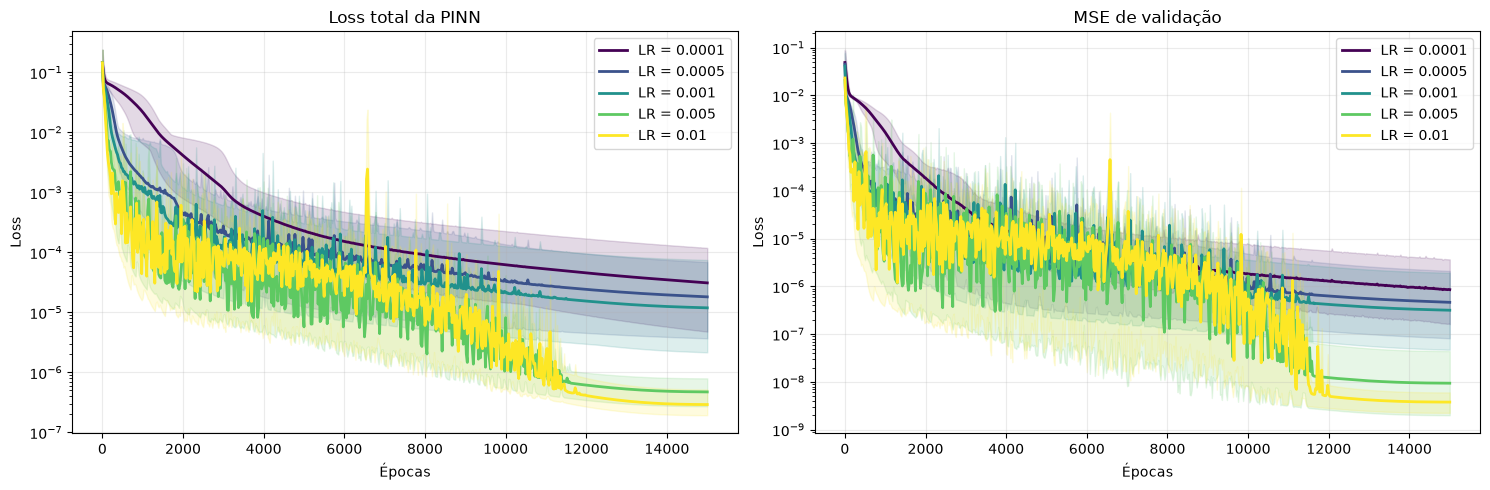

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, coluna, titulo in zip(
    axes,
    ["train_mse", "val_mse"],
    ["Loss total da PINN", "MSE de validação"]
):

    if not df_lr.empty:

        for lr in lrs:
            dados = df_lr[df_lr["lr_config"] == lr]

            if dados.empty:
                continue

            stats = dados.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            x = stats.index.to_numpy()

            ax.plot(
                x,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cores[lr],
                linewidth=2,
                label=f"LR = {lr}"
            )

            ax.fill_between(
                x,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cores[lr],
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Loss PDE, IC e BC

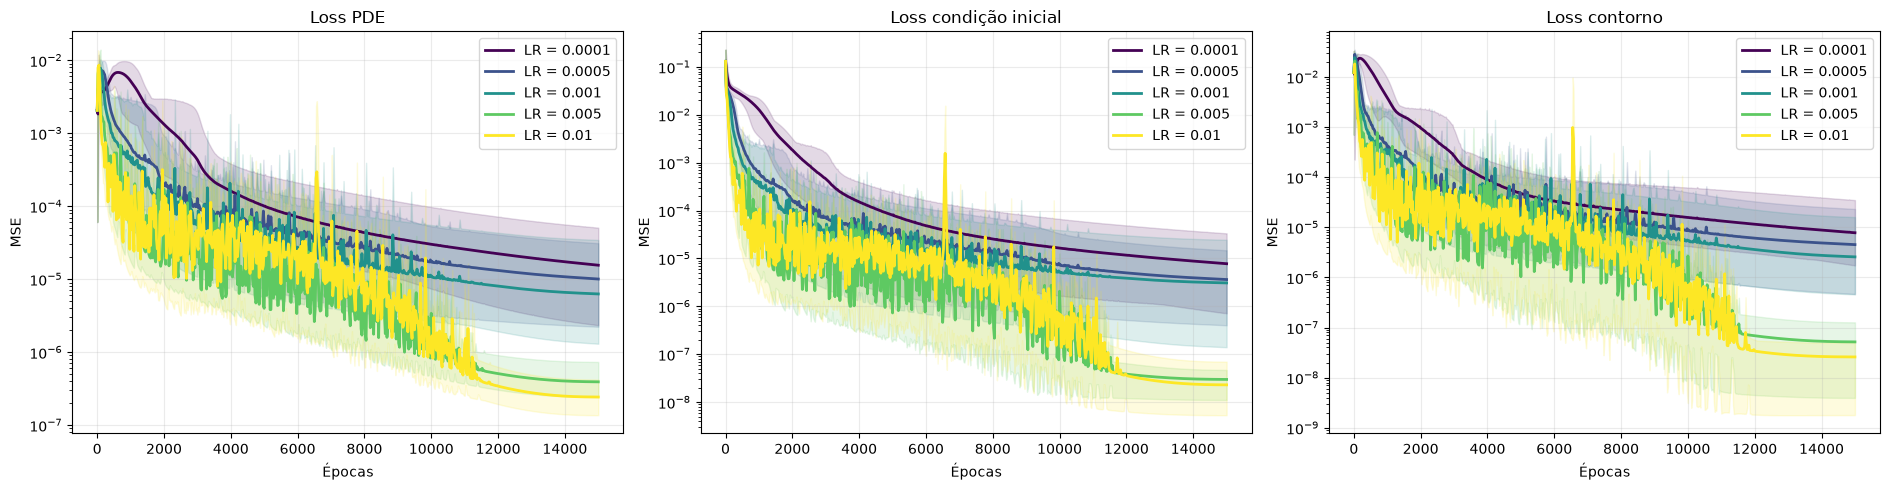

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

componentes = [
    ("loss_pde", "Loss PDE"),
    ("loss_ic", "Loss condição inicial"),
    ("loss_bc", "Loss contorno")
]

for ax, (coluna, titulo) in zip(axes, componentes):

    if not df_lr.empty:

        for lr in lrs:
            dados = df_lr[df_lr["lr_config"] == lr]

            if dados.empty:
                continue

            stats = dados.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            x = stats.index.to_numpy()

            ax.plot(
                x,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cores[lr],
                linewidth=2,
                label=f"LR = {lr}"
            )

            ax.fill_between(
                x,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cores[lr],
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Gradientes

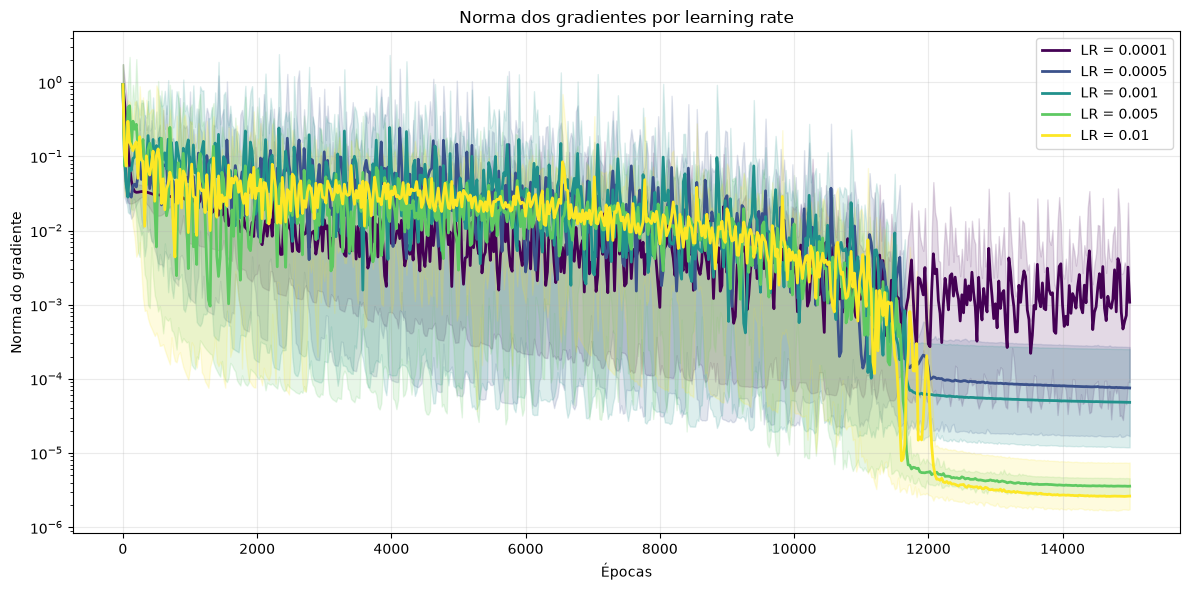

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

if not df_lr.empty:

    for lr in lrs:
        dados = df_lr[df_lr["lr_config"] == lr]

        if dados.empty:
            continue

        stats = dados.groupby("epoch")["grad_classical"].agg(
            ["mean", "min", "max"]
        )

        x = stats.index.to_numpy()

        ax.plot(
            x,
            np.maximum(stats["mean"].to_numpy(), 1e-15),
            color=cores[lr],
            linewidth=2,
            label=f"LR = {lr}"
        )

        ax.fill_between(
            x,
            np.maximum(stats["min"].to_numpy(), 1e-15),
            np.maximum(stats["max"].to_numpy(), 1e-15),
            color=cores[lr],
            alpha=0.15
        )

ax.set_title("Norma dos gradientes por learning rate")
ax.set_xlabel("Épocas")
ax.set_ylabel("Norma do gradiente")
ax.grid(alpha=0.25)

if ax.has_data():
    ax.set_yscale("log")
    ax.legend()

plt.tight_layout()
plt.show()

### RMSE médio e amplitude

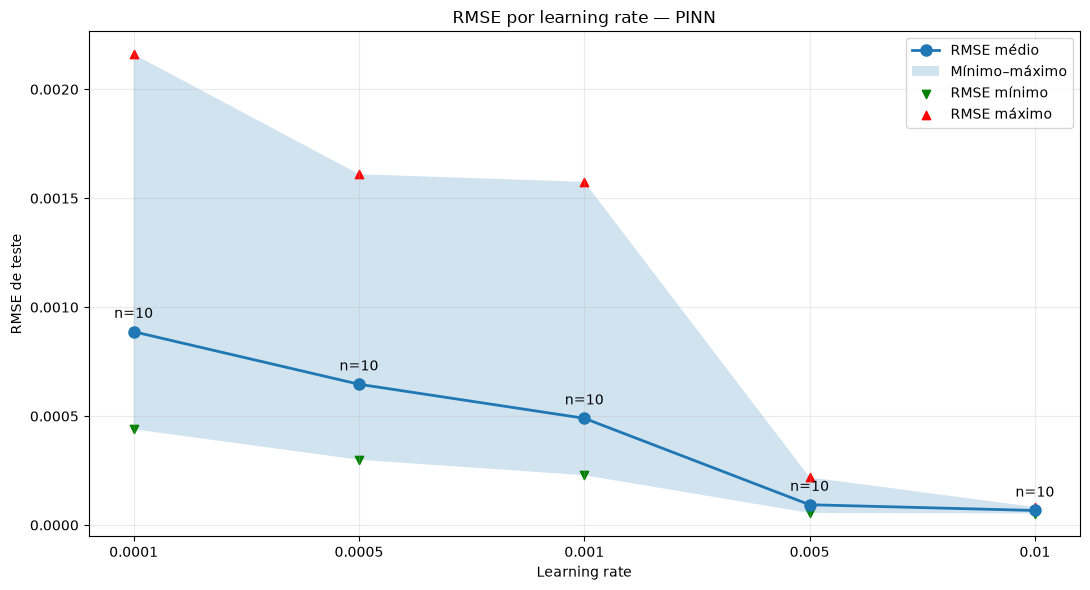

In [ ]:
if not resultados_lr.empty:

    stats = (
        resultados_lr.groupby("lr_config")["rmse"]
        .agg(["mean", "min", "max", "count"])
        .reindex(lrs)
        .dropna(subset=["mean"])
    )

    x = np.arange(len(stats))

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.plot(
        x, stats["mean"].to_numpy(),
        "o-", linewidth=2, markersize=8,
        label="RMSE médio"
    )

    ax.fill_between(
        x,
        stats["min"].to_numpy(),
        stats["max"].to_numpy(),
        alpha=0.2,
        label="Mínimo–máximo"
    )

    ax.scatter(
        x, stats["min"],
        marker="v", color="green",
        label="RMSE mínimo"
    )

    ax.scatter(
        x, stats["max"],
        marker="^", color="red",
        label="RMSE máximo"
    )

    for i, (_, linha) in enumerate(stats.iterrows()):
        ax.annotate(
            f"n={int(linha['count'])}",
            (i, linha["mean"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

    ax.set_xticks(x)
    ax.set_xticklabels(stats.index)
    ax.set_xlabel("Learning rate")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("RMSE por learning rate — PINN")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

else:
    print("Ainda não existem treinamentos concluídos.")

### Boxplot do RMSE

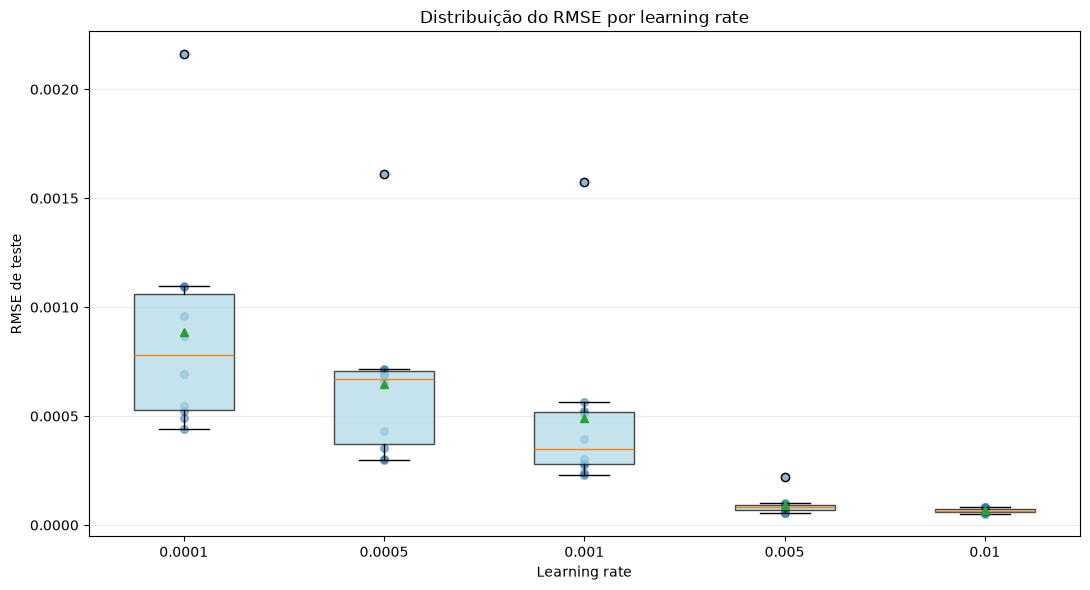

In [ ]:
if not resultados_lr.empty:

    grupos = [
        resultados_lr.loc[
            resultados_lr["lr_config"] == lr,
            "rmse"
        ].dropna().to_numpy()
        for lr in lrs
    ]

    posicoes = [i for i, grupo in enumerate(grupos) if len(grupo)]
    dados_box = [grupos[i] for i in posicoes]

    fig, ax = plt.subplots(figsize=(11, 6))

    if dados_box:
        bp = ax.boxplot(
            dados_box,
            positions=posicoes,
            widths=0.5,
            patch_artist=True,
            showmeans=True,
            manage_ticks=False
        )

        for patch in bp["boxes"]:
            patch.set_facecolor("lightblue")
            patch.set_alpha(0.7)

        for pos, grupo in zip(posicoes, dados_box):
            ax.scatter(
                np.full(len(grupo), pos),
                grupo,
                alpha=0.5,
                s=30,
                color="tab:blue"
            )

    ax.set_xticks(range(len(lrs)))
    ax.set_xticklabels(lrs)
    ax.set_xlabel("Learning rate")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("Distribuição do RMSE por learning rate")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

### RMSE por semente

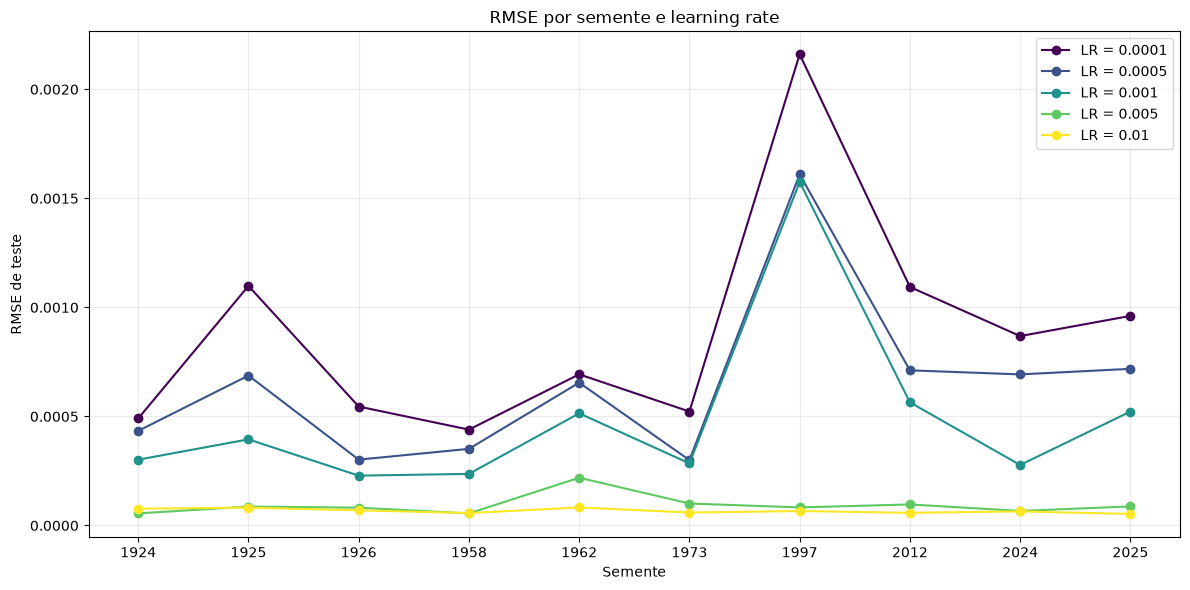

In [ ]:
if not resultados_lr.empty:

    fig, ax = plt.subplots(figsize=(12, 6))

    for lr in lrs:

        dados = (
            resultados_lr[
                resultados_lr["lr_config"] == lr
            ]
            .sort_values("seed")
        )

        if dados.empty:
            continue

        ax.plot(
            dados["seed"].astype(str),
            dados["rmse"],
            "o-",
            color=cores[lr],
            linewidth=1.5,
            label=f"LR = {lr}"
        )

    ax.set_xlabel("Semente")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("RMSE por semente e learning rate")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

### Tabela consolidada

In [ ]:
if not resultados_lr.empty:

    resumo_lr = (
        resultados_lr.groupby("lr_config")
        .agg(
            sementes=("seed", "nunique"),
            rmse_medio=("rmse", "mean"),
            rmse_std=("rmse", "std"),
            rmse_min=("rmse", "min"),
            rmse_max=("rmse", "max"),
            mae_medio=("mae", "mean"),
            l2_relativo=("relative_l2", "mean"),
            parametros=("parameters", "mean"),
            melhor_epoca=("best_epoch", "mean")
        )
        .reindex(lrs)
        .round(6)
    )

    display(resumo_lr)

,sementes,rmse_medio,rmse_std,rmse_min,rmse_max,mae_medio,l2_relativo,parametros,melhor_epoca
lr_config,,,,,,,,,
0.0001,10,0.000887,0.000512,0.000440,0.002161,0.000514,0.004008,3297.0,14900.0
0.0005,10,0.000646,0.000382,0.000300,0.001610,0.000382,0.002919,3297.0,15000.0
0.001,10,0.000490,0.000401,0.000229,0.001575,0.000296,0.002214,3297.0,15000.0
0.005,10,0.000093,0.000047,0.000055,0.000219,0.000053,0.000421,3297.0,15000.0
0.01,10,0.000067,0.000011,0.000053,0.000083,0.000036,0.000302,3297.0,14992.5


### 2.5. Hiperparâmetros finais da referência

| Item | Valor |
|---|---:|
| Camadas ocultas | 4 |
| Neurônios por camada | 32 |
| Ativação | Tanh |
| Épocas | 15.000 |
| Learning rate inicial | 0,005 |
| Scheduler | Cosine Annealing |
| Pontos interiores de colocação | 1.000 |
| Pontos de condição inicial | 100 |
| Pontos por fronteira | 100 |
| Validação | 300 pontos |
| Malha de teste | $250	imes250$ |
| Sementes planejadas | 10 |

**Escolhas adicionais:** o scheduler Cosine Annealing e o uso de 1.000 pontos de colocação foram mantidos após suas respectivas comparações. As células específicas dessas duas ablações não constavam do notebook enviado; portanto, não foram inventadas aqui.

## 3. Ablações da PINN-MPC quântica

O modelo híbrido combina uma MLP com cinco saídas $y_i(x,t)$ e um circuito quântico parametrizado que fornece cinco coeficientes $c_i$. Estudam-se qubits, profundidade quântica, observáveis e acoplamento.

No acoplamento polinomial: $\hat u(x,t)=\frac{1}{5}\sum_{i=1}^{5}(1+y_i)c_i^i$. No produto cumulativo: $\hat u(x,t)=\frac{1}{5}\sum_{i=1}^{5}(1+y_i)\prod_{j=1}^{i}c_j$.

Para a análise dos observáveis e dos acoplamentos, usam-se **5 qubits e 3 camadas quânticas**. Os treinamentos foram organizados em `mpc_serial`.

### Carregar as quatro etapas

A etapa de profundidade complementa a varredura de 3 camadas da etapa de qubits.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pasta = Path(
    "/home/camaral/inct_cq_hybrid_nn/runs/pinn/mpc_serial"
)

etapas = [
    "01_qubits",
    "02_layers",
    "03_observables",
    "04_couplings"
]

historicos = []
metricas = []

for etapa in etapas:

    diretorio = pasta / etapa

    for arquivo in sorted(diretorio.glob("*/seed_*/history.csv")):

        temp = pd.read_csv(arquivo)

        partes = arquivo.parent.parent.name.split("_")

        temp["stage"] = etapa
        temp["n_qubits"] = int(partes[0][1:])
        temp["layers"] = int(partes[1][1:])
        temp["observable"] = partes[2]
        temp["coupling"] = partes[3]
        temp["seed"] = int(arquivo.parent.name.split("_")[-1])

        historicos.append(temp)

    for arquivo in sorted(diretorio.glob("*/seed_*/metrics.json")):

        with open(arquivo) as f:
            m = json.load(f)

        m["stage"] = etapa
        m["seed"] = int(arquivo.parent.name.split("_")[-1])

        metricas.append(m)

df = (
    pd.concat(historicos, ignore_index=True)
    if historicos else pd.DataFrame()
)

resultados = pd.DataFrame(metricas)

esperados = {
    "01_qubits": 30,
    "02_layers": 60,
    "03_observables": 50,
    "04_couplings": 20
}

progresso = pd.DataFrame([
    {
        "etapa": etapa,
        "concluidos": (
            int((resultados["stage"] == etapa).sum())
            if not resultados.empty else 0
        ),
        "esperados": total
    }
    for etapa, total in esperados.items()
])

progresso["percentual"] = (
    100 * progresso["concluidos"] / progresso["esperados"]
)

print("Históricos encontrados:", len(historicos))
print("Resultados disponíveis:", len(metricas), "/160")

display(progresso)

if not resultados.empty:
    display(
        resultados.groupby("stage")["rmse"]
        .agg(["count", "mean", "std", "min", "max"])
        .round(6)
    )

Históricos encontrados: 118
Resultados disponíveis: 117 /160


,etapa,concluidos,esperados,percentual
0,01_qubits,30,30,100.0
1,02_layers,60,60,100.0
2,03_observables,27,50,54.0
3,04_couplings,0,20,0.0


,count,mean,std,min,max
stage,,,,,
01_qubits,30,0.000076,0.000019,0.000047,0.000125
02_layers,60,0.000076,0.000023,0.000041,0.000144
03_observables,27,0.000059,0.000016,0.000025,0.000086


### Etapa 1 — RMSE por número de qubits

Qubits 3, 5 e 7, com três camadas.

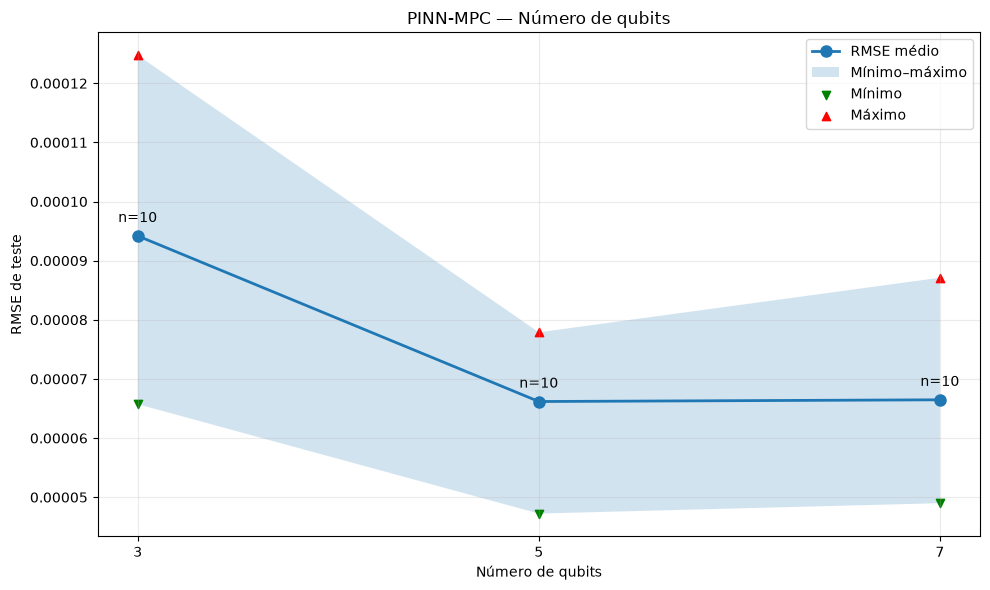

In [ ]:
dados = resultados[
    resultados["stage"] == "01_qubits"
].copy()

if not dados.empty:

    qubits = [3, 5, 7]

    stats = (
        dados.groupby("n_qubits")["rmse"]
        .agg(["mean", "min", "max", "count"])
        .reindex(qubits)
        .dropna(subset=["mean"])
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(len(stats))

    ax.plot(
        x, stats["mean"],
        "o-", linewidth=2, markersize=8,
        label="RMSE médio"
    )

    ax.fill_between(
        x,
        stats["min"].to_numpy(),
        stats["max"].to_numpy(),
        alpha=0.2,
        label="Mínimo–máximo"
    )

    ax.scatter(
        x, stats["min"],
        marker="v", color="green",
        label="Mínimo"
    )

    ax.scatter(
        x, stats["max"],
        marker="^", color="red",
        label="Máximo"
    )

    for i, (_, linha) in enumerate(stats.iterrows()):
        ax.annotate(
            f"n={int(linha['count'])}",
            (i, linha["mean"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

    ax.set_xticks(x)
    ax.set_xticklabels(stats.index)
    ax.set_xlabel("Número de qubits")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("PINN-MPC — Número de qubits")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

### Etapa 2 — RMSE por profundidade quântica

Combina as etapas 1 e 2 para obter a grade 3 × 3.

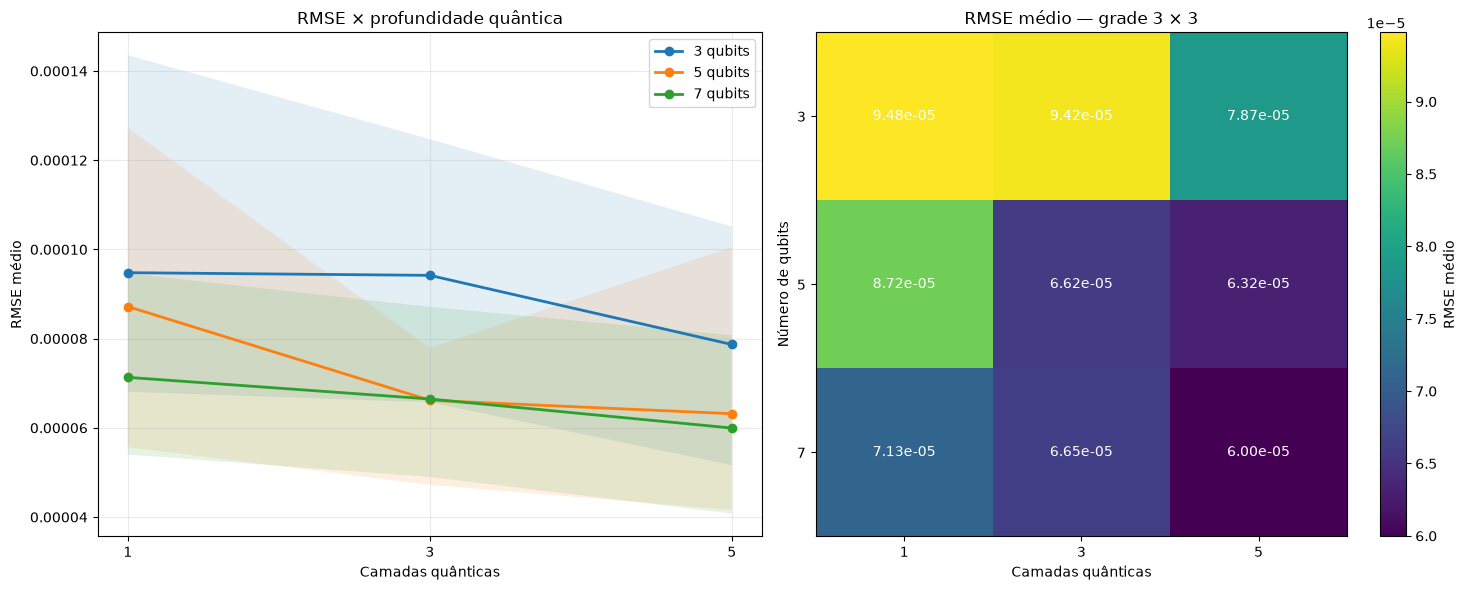

mean       std       min       max  count
n_qubits layers                                               
3        1       0.000095  0.000027  0.000068  0.000144     10
         3       0.000094  0.000018  0.000066  0.000125     10
         5       0.000079  0.000019  0.000052  0.000105     10
5        1       0.000087  0.000024  0.000056  0.000127     10
         3       0.000066  0.000011  0.000047  0.000078     10
         5       0.000063  0.000016  0.000042  0.000100     10
7        1       0.000071  0.000015  0.000054  0.000095     10
         3       0.000066  0.000012  0.000049  0.000087     10
         5       0.000060  0.000012  0.000041  0.000081     10

In [ ]:
dados = resultados[
    resultados["stage"].isin(["01_qubits", "02_layers"])
].copy()

if not dados.empty:

    resumo = (
        dados.groupby(["n_qubits", "layers"])["rmse"]
        .agg(["mean", "std", "min", "max", "count"])
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # Gráfico de linhas
    for q in [3, 5, 7]:

        if q not in resumo.index.get_level_values(0):
            continue

        temp = resumo.loc[q]

        axes[0].plot(
            temp.index,
            temp["mean"],
            "o-",
            linewidth=2,
            label=f"{q} qubits"
        )

        axes[0].fill_between(
            temp.index.to_numpy(),
            temp["min"].to_numpy(),
            temp["max"].to_numpy(),
            alpha=0.12
        )

    axes[0].set_xticks([1, 3, 5])
    axes[0].set_xlabel("Camadas quânticas")
    axes[0].set_ylabel("RMSE médio")
    axes[0].set_title("RMSE × profundidade quântica")
    axes[0].grid(alpha=0.25)
    axes[0].legend()

    # Heatmap
    matriz = (
        dados.pivot_table(
            index="n_qubits",
            columns="layers",
            values="rmse",
            aggfunc="mean"
        )
        .reindex(index=[3, 5, 7], columns=[1, 3, 5])
    )

    im = axes[1].imshow(
        matriz.to_numpy(),
        cmap="viridis",
        aspect="auto"
    )

    axes[1].set_xticks(range(3))
    axes[1].set_xticklabels([1, 3, 5])
    axes[1].set_yticks(range(3))
    axes[1].set_yticklabels([3, 5, 7])

    axes[1].set_xlabel("Camadas quânticas")
    axes[1].set_ylabel("Número de qubits")
    axes[1].set_title("RMSE médio — grade 3 × 3")

    for i in range(3):
        for j in range(3):

            valor = matriz.iloc[i, j]

            if pd.notna(valor):
                axes[1].text(
                    j, i, f"{valor:.2e}",
                    ha="center",
                    va="center",
                    color="white"
                )

    fig.colorbar(im, ax=axes[1], label="RMSE médio")

    plt.tight_layout()
    plt.show()

    display(resumo.round(6))

### Etapa 3 — Observáveis de Pauli

Compara Z, ZZ, XX, YY e Mixed com 5 qubits e 3 camadas.

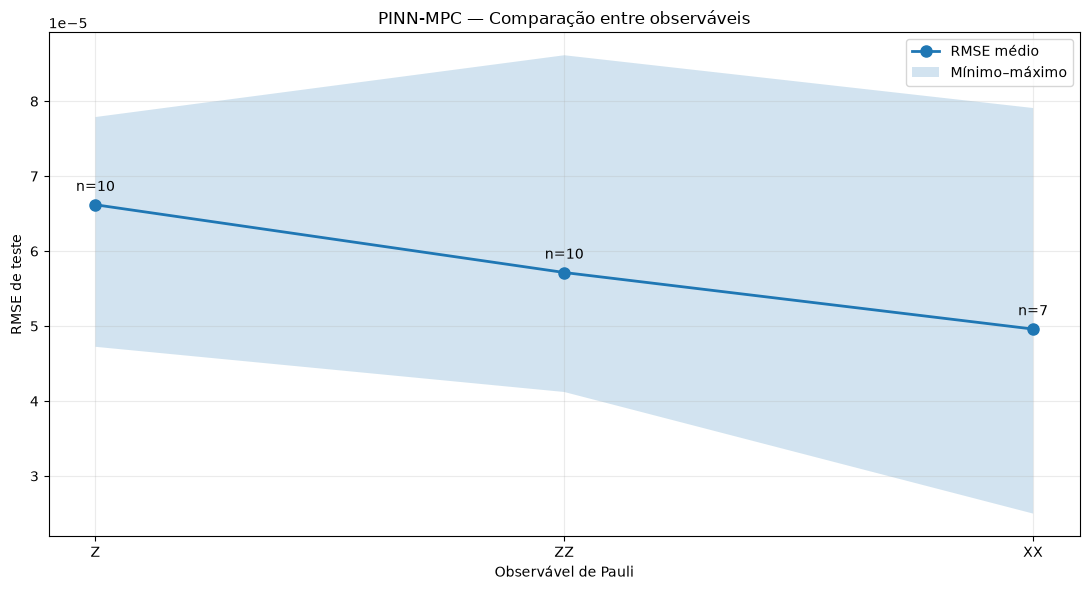

In [ ]:
dados = resultados[
    resultados["stage"] == "03_observables"
].copy()

observaveis = ["z", "zz", "xx", "yy", "mixed"]

if not dados.empty:

    stats = (
        dados.groupby("observable")["rmse"]
        .agg(["mean", "min", "max", "count"])
        .reindex(observaveis)
        .dropna(subset=["mean"])
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    x = np.arange(len(stats))

    ax.plot(
        x, stats["mean"],
        "o-", linewidth=2, markersize=8,
        label="RMSE médio"
    )

    ax.fill_between(
        x, stats["min"].to_numpy(),
        stats["max"].to_numpy(),
        alpha=0.2,
        label="Mínimo–máximo"
    )

    for i, (_, linha) in enumerate(stats.iterrows()):
        ax.annotate(
            f"n={int(linha['count'])}",
            (i, linha["mean"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

    ax.set_xticks(x)
    ax.set_xticklabels(stats.index.str.upper())
    ax.set_xlabel("Observável de Pauli")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("PINN-MPC — Comparação entre observáveis")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

### Etapa 4 — Tipos de acoplamento

Compara polinomial e produto cumulativo.

In [ ]:
dados = resultados[
    resultados["stage"] == "04_couplings"
].copy()

acoplamentos = ["polynomial", "product"]

if not dados.empty:

    stats = (
        dados.groupby("coupling")["rmse"]
        .agg(["mean", "std", "min", "max", "count"])
        .reindex(acoplamentos)
        .dropna(subset=["mean"])
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(len(stats))

    ax.plot(
        x, stats["mean"],
        "o-", linewidth=2, markersize=8,
        label="RMSE médio"
    )

    ax.fill_between(
        x,
        stats["min"].to_numpy(),
        stats["max"].to_numpy(),
        alpha=0.2,
        label="Mínimo–máximo"
    )

    for i, (_, linha) in enumerate(stats.iterrows()):
        ax.annotate(
            f"n={int(linha['count'])}",
            (i, linha["mean"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

    ax.set_xticks(x)
    ax.set_xticklabels(["Polinomial", "Produto cumulativo"])
    ax.set_xlabel("Tipo de acoplamento")
    ax.set_ylabel("RMSE de teste")
    ax.set_title("PINN-MPC — Comparação dos acoplamentos")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

    display(stats.round(6))

### Loss total e validação por etapa

Altere `etapa_plot` para selecionar qual ablação será exibida.

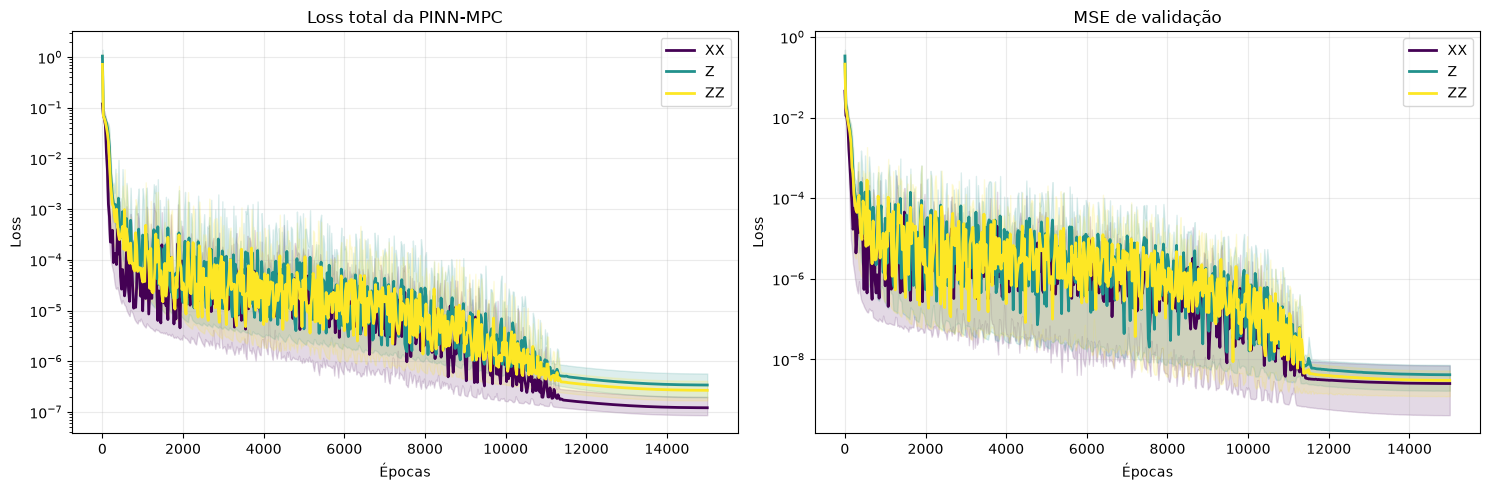

In [ ]:
etapa_plot = "03_observables"

def preparar_plot(df, etapa):

    dados = df[df["stage"] == etapa].copy()

    if etapa == "01_qubits":
        dados["config"] = dados["n_qubits"].astype(str) + " qubits"

    elif etapa in ("02_layers",):
        dados["config"] = (
            dados["n_qubits"].astype(str) + "q / "
            + dados["layers"].astype(str) + "L"
        )

    elif etapa == "03_observables":
        dados["config"] = dados["observable"].str.upper()

    else:
        dados["config"] = dados["coupling"]

    return dados


dados_plot = (
    preparar_plot(df, etapa_plot)
    if not df.empty else pd.DataFrame()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, coluna, titulo in zip(
    axes,
    ["train_mse", "val_mse"],
    ["Loss total da PINN-MPC", "MSE de validação"]
):

    if not dados_plot.empty:

        configs = sorted(dados_plot["config"].unique())
        cores = plt.cm.viridis(np.linspace(0, 1, len(configs)))

        for config, cor in zip(configs, cores):

            temp = dados_plot[
                dados_plot["config"] == config
            ]

            stats = temp.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            x = stats.index.to_numpy()

            ax.plot(
                x,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cor,
                linewidth=2,
                label=config
            )

            ax.fill_between(
                x,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cor,
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Componentes PDE, IC e BC

Reutiliza a seleção feita na célula anterior.

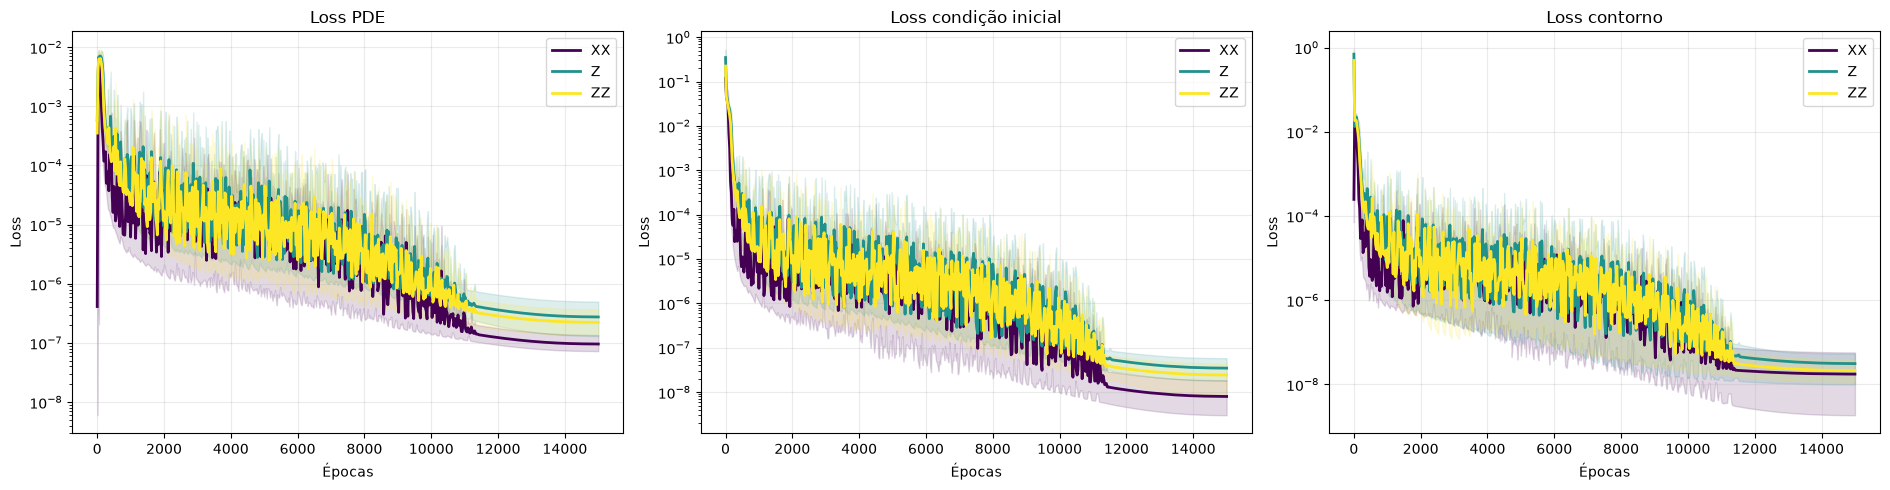

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

componentes = [
    ("loss_pde", "Loss PDE"),
    ("loss_ic", "Loss condição inicial"),
    ("loss_bc", "Loss contorno")
]

for ax, (coluna, titulo) in zip(axes, componentes):

    if not dados_plot.empty:

        configs = sorted(dados_plot["config"].unique())
        cores = plt.cm.viridis(np.linspace(0, 1, len(configs)))

        for config, cor in zip(configs, cores):

            temp = dados_plot[
                dados_plot["config"] == config
            ]

            stats = temp.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            x = stats.index.to_numpy()

            ax.plot(
                x,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cor,
                linewidth=2,
                label=config
            )

            ax.fill_between(
                x,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cor,
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Gradientes clássicos e quânticos

Separa os gradientes do bloco clássico e do circuito.

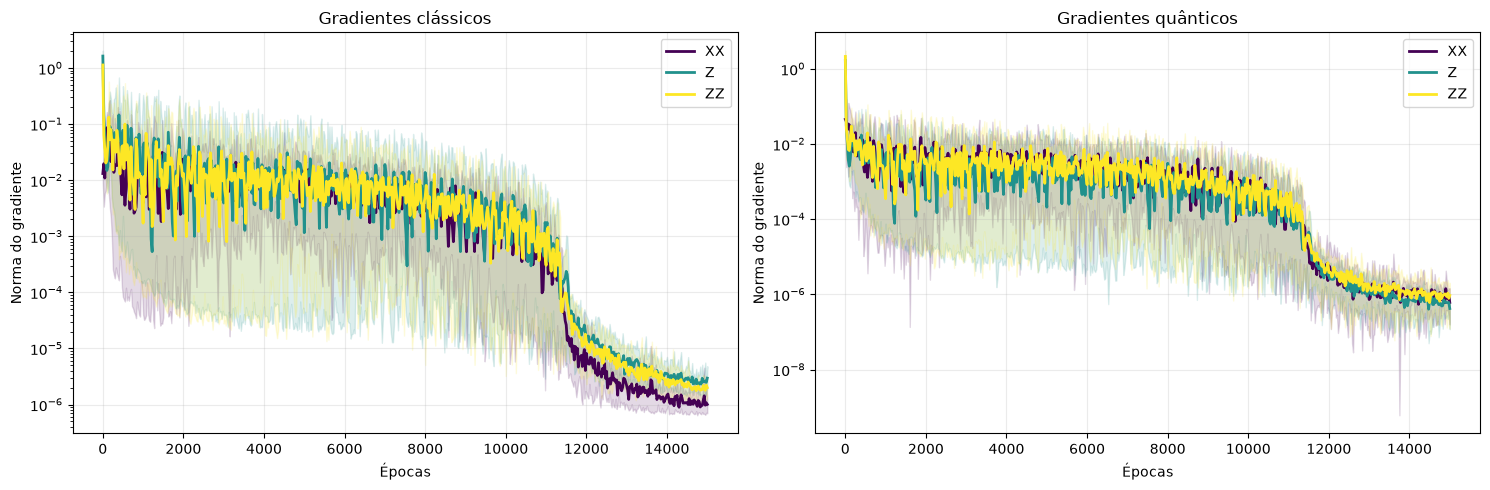

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

gradientes = [
    ("grad_classical", "Gradientes clássicos"),
    ("grad_quantum", "Gradientes quânticos")
]

for ax, (coluna, titulo) in zip(axes, gradientes):

    if not dados_plot.empty:

        configs = sorted(dados_plot["config"].unique())
        cores = plt.cm.viridis(np.linspace(0, 1, len(configs)))

        for config, cor in zip(configs, cores):

            temp = dados_plot[
                dados_plot["config"] == config
            ]

            stats = temp.groupby("epoch")[coluna].agg(
                ["mean", "min", "max"]
            )

            x = stats.index.to_numpy()

            ax.plot(
                x,
                np.maximum(stats["mean"].to_numpy(), 1e-15),
                color=cor,
                linewidth=2,
                label=config
            )

            ax.fill_between(
                x,
                np.maximum(stats["min"].to_numpy(), 1e-15),
                np.maximum(stats["max"].to_numpy(), 1e-15),
                color=cor,
                alpha=0.15
            )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Norma do gradiente")
    ax.grid(alpha=0.25)

    if ax.has_data():
        ax.set_yscale("log")
        ax.legend()

plt.tight_layout()
plt.show()

### Boxplots das quatro etapas

Distribuições do RMSE por família de configurações.

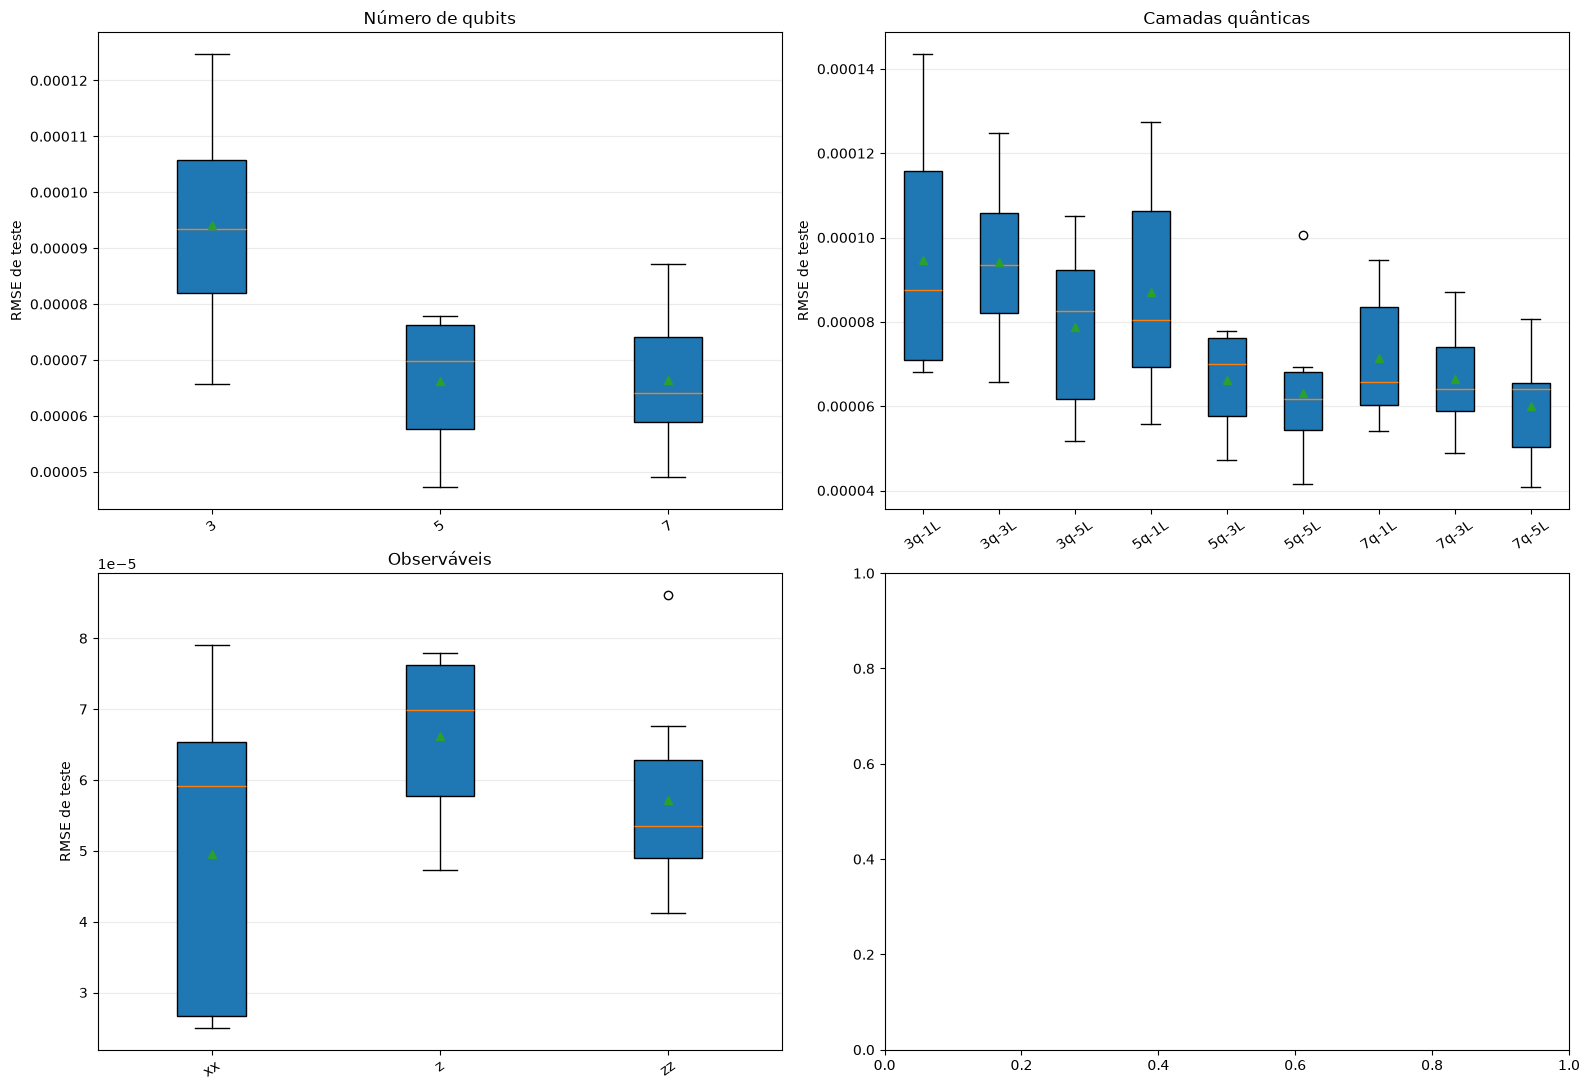

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

experimentos = [
    ("01_qubits", "Número de qubits", "n_qubits"),
    ("02_layers", "Camadas quânticas", "layers"),
    ("03_observables", "Observáveis", "observable"),
    ("04_couplings", "Acoplamentos", "coupling")
]

for ax, (etapa, titulo, coluna) in zip(axes.flat, experimentos):

    if resultados.empty:
        continue

    if etapa == "02_layers":
        # A grade de camadas inclui também a etapa 1
        dados = resultados[
            resultados["stage"].isin(["01_qubits", "02_layers"])
        ].copy()

        dados["config"] = (
            dados["n_qubits"].astype(str) + "q-"
            + dados["layers"].astype(str) + "L"
        )

    else:
        dados = resultados[
            resultados["stage"] == etapa
        ].copy()

        dados["config"] = dados[coluna].astype(str)

    if dados.empty:
        continue

    configs = sorted(dados["config"].unique())

    grupos = [
        dados.loc[
            dados["config"] == c, "rmse"
        ].dropna().to_numpy()
        for c in configs
    ]

    ax.boxplot(
        grupos,
        tick_labels=configs,
        showmeans=True,
        patch_artist=True
    )

    ax.set_title(titulo)
    ax.set_ylabel("RMSE de teste")
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

### RMSE versus número de parâmetros

Desconsidera configurações duplicadas em etapas diferentes.

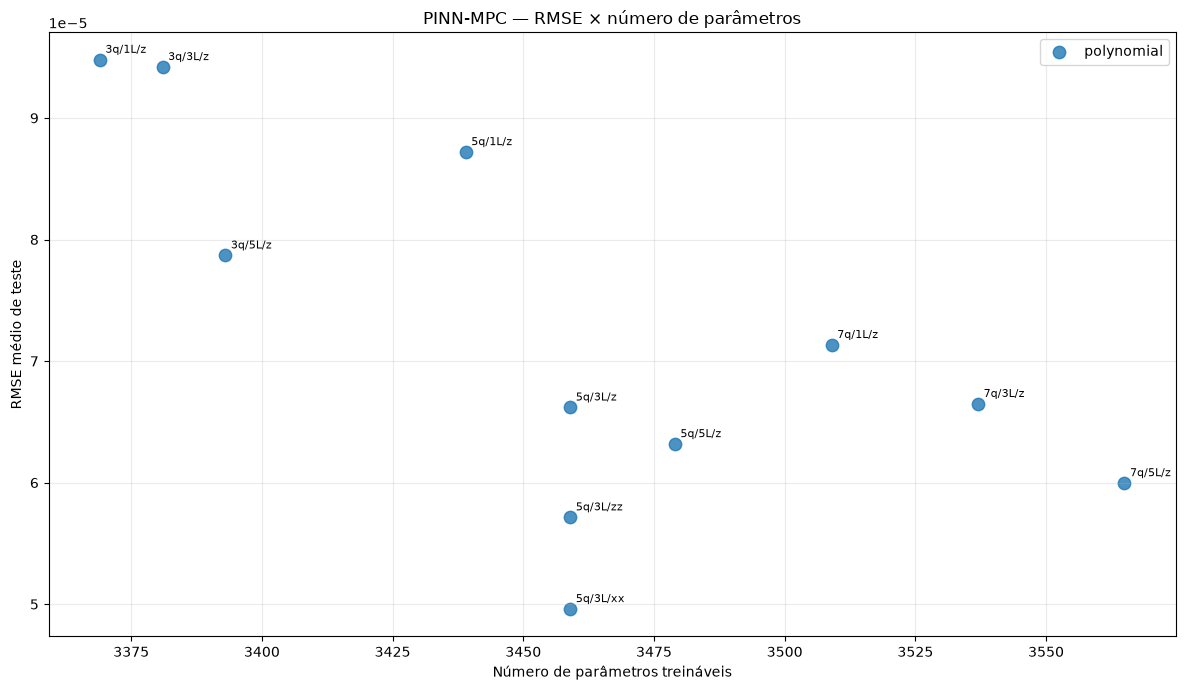

In [ ]:
if not resultados.empty:

    dados = resultados.drop_duplicates(
        subset=[
            "n_qubits", "layers",
            "observable", "coupling", "seed"
        ]
    )

    resumo = (
        dados.groupby(
            ["n_qubits", "layers", "observable", "coupling"]
        )
        .agg(
            parametros=("parameters", "mean"),
            rmse=("rmse", "mean"),
            sementes=("seed", "nunique")
        )
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(12, 7))

    for coupling, grupo in resumo.groupby("coupling"):

        ax.scatter(
            grupo["parametros"],
            grupo["rmse"],
            s=80,
            alpha=0.8,
            label=coupling
        )

    for _, linha in resumo.iterrows():

        rotulo = (
            f"{linha['n_qubits']}q/"
            f"{linha['layers']}L/"
            f"{linha['observable']}"
        )

        ax.annotate(
            rotulo,
            (linha["parametros"], linha["rmse"]),
            xytext=(4, 5),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_xlabel("Número de parâmetros treináveis")
    ax.set_ylabel("RMSE médio de teste")
    ax.set_title("PINN-MPC — RMSE × número de parâmetros")
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

### Solução exata, PINN-MPC e erro

Reconstrói o melhor checkpoint existente entre os resultados disponíveis.

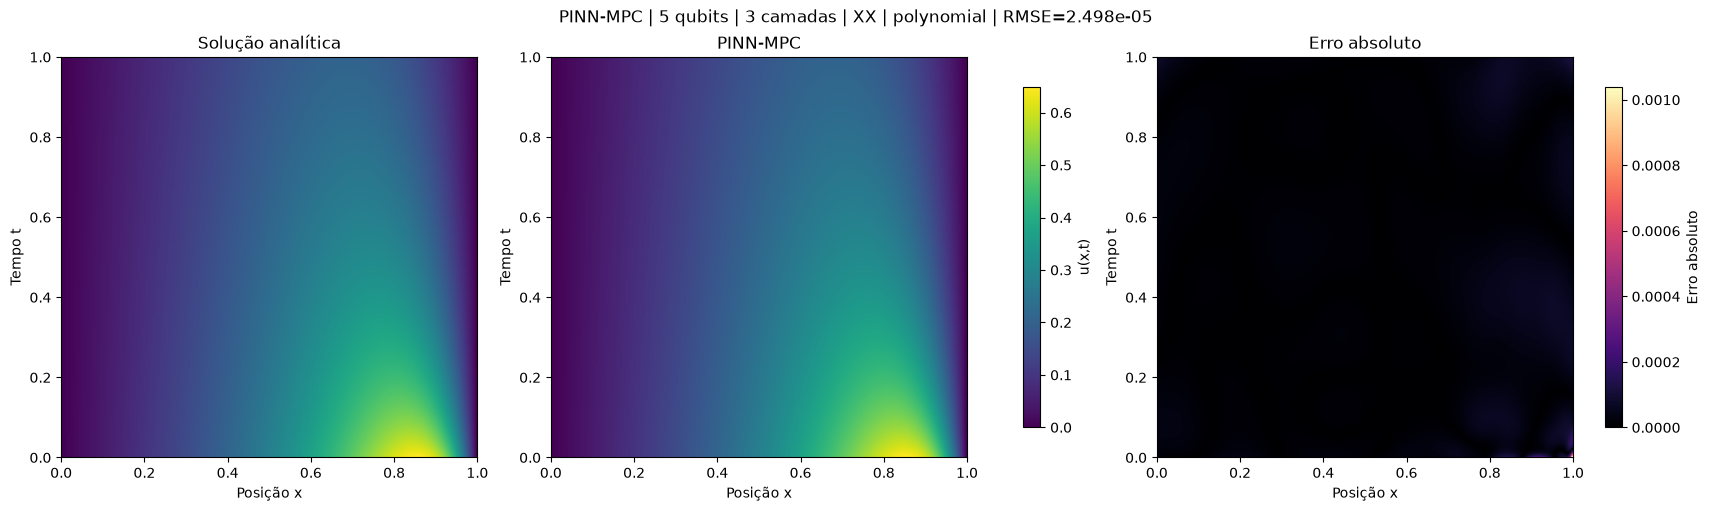

Etapa: 03_observables
Qubits: 5
Camadas: 3
Observável: xx
Acoplamento: polynomial
Semente: 1926
Parâmetros: 3459
RMSE: 2.498271e-05


In [ ]:
import sys
import torch

projeto = Path("/home/camaral/inct_cq_hybrid_nn")
sys.path.insert(0, str(projeto))

from pinn_mpc_serial import MPCPINN, exact

if not resultados.empty:

    melhor = resultados.loc[resultados["rmse"].idxmin()]

    etapa = melhor["stage"]
    nq = int(melhor["n_qubits"])
    layers = int(melhor["layers"])
    obs = melhor["observable"]
    coupling = melhor["coupling"]
    seed = int(melhor["seed"])

    arquivo = (
        pasta / etapa
        / f"q{nq}_l{layers}_{obs}_{coupling}"
        / f"seed_{seed}" / "best.pt"
    )

    modelo = MPCPINN(
        n_qubits=nq,
        qlayers=layers,
        observable=obs,
        coupling=coupling,
        depth=int(melhor["depth"]),
        width=int(melhor["width"])
    )

    modelo.load_state_dict(
        torch.load(
            arquivo,
            map_location="cpu",
            weights_only=True
        )
    )

    modelo.eval()

    n = 250

    x = np.linspace(0, 1, n)
    t = np.linspace(0, 1, n)

    X, T = np.meshgrid(x, t, indexing="ij")

    coords = torch.tensor(
        np.column_stack([X.ravel(), T.ravel()]),
        dtype=torch.float32
    )

    with torch.no_grad():

        exata = exact(coords).numpy().reshape(n, n)

        prevista = torch.cat([
            modelo(parte)
            for parte in coords.split(4096)
        ]).numpy().reshape(n, n)

    erro = np.abs(prevista - exata)
    rmse = np.sqrt(np.mean((prevista - exata)**2))

    vmin = min(exata.min(), prevista.min())
    vmax = max(exata.max(), prevista.max())

    fig, axes = plt.subplots(
        1, 3, figsize=(17, 5),
        constrained_layout=True
    )

    im0 = axes[0].imshow(
        exata.T,
        origin="lower",
        extent=[0, 1, 0, 1],
        cmap="viridis",
        vmin=vmin, vmax=vmax,
        aspect="auto"
    )

    axes[1].imshow(
        prevista.T,
        origin="lower",
        extent=[0, 1, 0, 1],
        cmap="viridis",
        vmin=vmin, vmax=vmax,
        aspect="auto"
    )

    im2 = axes[2].imshow(
        erro.T,
        origin="lower",
        extent=[0, 1, 0, 1],
        cmap="magma",
        aspect="auto"
    )

    for ax, titulo in zip(
        axes,
        ["Solução analítica", "PINN-MPC", "Erro absoluto"]
    ):
        ax.set_title(titulo)
        ax.set_xlabel("Posição x")
        ax.set_ylabel("Tempo t")

    fig.colorbar(
        im0, ax=axes[:2],
        shrink=0.85, label="u(x,t)"
    )

    fig.colorbar(
        im2, ax=axes[2],
        shrink=0.85, label="Erro absoluto"
    )

    fig.suptitle(
        f"PINN-MPC | {nq} qubits | {layers} camadas | "
        f"{obs.upper()} | {coupling} | RMSE={rmse:.3e}"
    )

    plt.show()

    print("Etapa:", etapa)
    print("Qubits:", nq)
    print("Camadas:", layers)
    print("Observável:", obs)
    print("Acoplamento:", coupling)
    print("Semente:", seed)
    print("Parâmetros:", int(melhor["parameters"]))
    print(f"RMSE: {rmse:.6e}")

### Tabelas consolidadas

Resumo por qubits/camadas, observáveis e acoplamentos.

In [ ]:
if not resultados.empty:

    dados = resultados.copy()

    # Reunir etapas 1 e 2 na análise da grade quântica
    grade = dados[
        dados["stage"].isin(["01_qubits", "02_layers"])
    ]

    observaveis = dados[
        dados["stage"] == "03_observables"
    ]

    acoplamentos = dados[
        dados["stage"] == "04_couplings"
    ]

    def tabela(dados, colunas):

        return (
            dados.groupby(colunas)
            .agg(
                sementes=("seed", "nunique"),
                rmse_medio=("rmse", "mean"),
                rmse_std=("rmse", "std"),
                rmse_min=("rmse", "min"),
                rmse_max=("rmse", "max"),
                mae_medio=("mae", "mean"),
                l2_relativo=("relative_l2", "mean"),
                parametros=("parameters", "mean"),
                melhor_epoca=("best_epoch", "mean")
            )
            .round(6)
        )

    print("1 e 2 — Qubits × camadas")
    display(
        tabela(grade, ["n_qubits", "layers"])
    )

    print("3 — Observáveis")
    display(
        tabela(observaveis, ["observable"])
    )

    print("4 — Acoplamentos")
    display(
        tabela(acoplamentos, ["coupling"])
    )

1 e 2 — Qubits × camadas


sementes  rmse_medio  rmse_std  rmse_min  rmse_max  \
n_qubits layers                                                       
3        1             10    0.000095  0.000027  0.000068  0.000144   
         3             10    0.000094  0.000018  0.000066  0.000125   
         5             10    0.000079  0.000019  0.000052  0.000105   
5        1             10    0.000087  0.000024  0.000056  0.000127   
         3             10    0.000066  0.000011  0.000047  0.000078   
         5             10    0.000063  0.000016  0.000042  0.000100   
7        1             10    0.000071  0.000015  0.000054  0.000095   
         3             10    0.000066  0.000012  0.000049  0.000087   
         5             10    0.000060  0.000012  0.000041  0.000081   

                 mae_medio  l2_relativo  parametros  melhor_epoca  
n_qubits layers                                                    
3        1        0.000054     0.000428      3369.0       14997.5  
         3        0.000055     0.000425      3381.0       14997.5  
         5        0.000049     0.000355      3393.0       14985.0  
5        1        0.000054     0.000394      3439.0       14992.5  
         3        0.000040     0.000299      3459.0       14962.5  
         5        0.000039     0.000285      3479.0       14960.0  
7        1        0.000044     0.000322      3509.0       14962.5  
         3        0.000041     0.000300      3537.0       14922.5  
         5        0.000035     0.000271      3565.0       14945.0

3 — Observáveis


,sementes,rmse_medio,rmse_std,rmse_min,rmse_max,mae_medio,l2_relativo,parametros,melhor_epoca
observable,,,,,,,,,
xx,7,0.000050,0.000023,0.000025,0.000079,0.000026,0.000224,3459.0,14921.428571
z,10,0.000066,0.000011,0.000047,0.000078,0.000040,0.000299,3459.0,14962.500000
zz,10,0.000057,0.000013,0.000041,0.000086,0.000033,0.000258,3459.0,14970.000000


4 — Acoplamentos


,sementes,rmse_medio,rmse_std,rmse_min,rmse_max,mae_medio,l2_relativo,parametros,melhor_epoca
coupling,,,,,,,,,


## 4. Controle clássico: MPC com duas MLPs

Para isolar o papel do gerador quântico de coeficientes, o circuito é substituído por uma **segunda MLP**, sem alterar a MLP principal nem o acoplamento por **produto cumulativo**.

A rede secundária recebe uma entrada constante e produz cinco coeficientes em $[-1,1]$; o circuito quântico de referência contém $5	imes3	imes2=30$ parâmetros variacionais. O controle clássico explora uma grade de **1, 2 ou 3 camadas ocultas** e **1, 2 ou 3 neurônios**, com números de parâmetros inferiores, próximos e superiores a 30.

A primeira comparação deve manter **5 qubits, 3 camadas, observáveis Mixed e acoplamento produto** para o MPC quântico, pois essa é a contraparte da MPC-MLP-MLP treinada.

### Carregamento dos três métodos

Carrega a MLP tradicional, as configurações quânticas 5q/3L e a grade MPC-MLP-MLP.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

base = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")

p_mlp = base / "mlp_depth_2706/results/burgers/pinn_mlp_depth_4"
p_quantum = base / "mpc_serial"
p_classic = base / "mpc_classical_product"


def carregar(arquivos):
    hs, ms = [], []

    for arq in sorted(arquivos):
        seed = int(arq.parent.name.split("_")[-1])

        with open(arq) as f:
            m = json.load(f)

        m["seed"] = seed
        m["arquivo"] = str(arq)
        ms.append(m)

        hist = arq.parent / "history.csv"

        if hist.exists():
            h = pd.read_csv(hist)
            h["seed"] = seed
            h["arquivo"] = str(arq)
            hs.append(h)

    return (
        pd.concat(hs, ignore_index=True) if hs else pd.DataFrame(),
        pd.DataFrame(ms)
    )


# MLP clássica
h_mlp, m_mlp = carregar(
    p_mlp.glob("seed_*/metrics.json")
)

# MPC quântico — todas as configurações 5q / 3L
h_q, m_q = carregar(
    p_quantum.glob("0*_*/q5_l3_*/seed_*/metrics.json")
)

# Remover execuções reaproveitadas entre etapas
if not m_q.empty:
    m_q = m_q.drop_duplicates(
        ["observable", "coupling", "seed"]
    )

# MPC com duas MLPs — grade 3x3
h_c, m_c = carregar(
    p_classic.glob("layers_*_width_*/seed_*/metrics.json")
)

print("MLP:", len(m_mlp))
print("MPC quântico 5q/3L:", len(m_q))
print("MPC-MLP-MLP:", len(m_c))

if not m_c.empty:
    display(
        m_c.groupby(["gen_layers", "gen_width"])
        .agg(
            sementes=("seed", "nunique"),
            parametros_gerador=("parameters_generator", "mean"),
            rmse_medio=("rmse", "mean"),
            rmse_std=("rmse", "std")
        ).round(6)
    )

MLP: 10
MPC quântico 5q/3L: 27
MPC-MLP-MLP: 77


sementes  parametros_gerador  rmse_medio  rmse_std
gen_layers gen_width                                                    
1          1                10                12.0    0.000045  0.000010
           2                10                19.0    0.000056  0.000023
           3                10                26.0    0.000040  0.000010
2          1                10                14.0    0.000050  0.000009
           2                10                25.0    0.000046  0.000017
           3                10                38.0    0.000046  0.000013
3          1                10                16.0    0.000052  0.000013
           2                 7                31.0    0.000059  0.000024

### Produto cumulativo — RMSE versus parâmetros do gerador

Compara o circuito quântico de 30 parâmetros com os geradores clássicos da grade 3 × 3.

In [ ]:
# MPC quântico equivalente: 5q, 3L, Mixed, produto
q_prod = m_q[
    (m_q["observable"] == "mixed") &
    (m_q["coupling"] == "product")
].copy()

if not q_prod.empty and not m_c.empty:

    stats = (
        m_c.groupby(["gen_layers", "gen_width"])
        .agg(
            rmse=("rmse", "mean"),
            rmse_min=("rmse", "min"),
            rmse_max=("rmse", "max"),
            params=("parameters_generator", "mean"),
            sementes=("seed", "nunique")
        )
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    for layers, grupo in stats.groupby("gen_layers"):

        grupo = grupo.sort_values("params")

        ax.plot(
            grupo["params"],
            grupo["rmse"],
            "o-",
            linewidth=2,
            markersize=8,
            label=f"MLP geradora — {layers} camadas"
        )

        ax.fill_between(
            grupo["params"],
            grupo["rmse_min"],
            grupo["rmse_max"],
            alpha=0.12
        )

    ax.axhline(
        q_prod["rmse"].mean(),
        color="black",
        linestyle="--",
        linewidth=2,
        label="MPC quântico — produto"
    )

    ax.axvline(
        30,
        color="gray",
        linestyle=":",
        label="30 parâmetros quânticos"
    )

    ax.set_xlabel("Parâmetros do gerador de coeficientes")
    ax.set_ylabel("RMSE médio de teste")
    ax.set_title("MPC quântico × MPC-MLP-MLP — produto cumulativo")
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

    display(stats.round(6))

else:
    print("Ainda faltam resultados concluídos para esta comparação.")

Ainda faltam resultados concluídos para esta comparação.


### Produto cumulativo — boxplots

Distribuição do RMSE do MPC quântico e de cada arquitetura do gerador clássico.

In [ ]:
if not q_prod.empty and not m_c.empty:

    grupos = [q_prod["rmse"].dropna().to_numpy()]
    nomes = ["MPC\nquântico"]

    for (layers, width), dados in m_c.groupby(
        ["gen_layers", "gen_width"]
    ):
        grupos.append(dados["rmse"].dropna().to_numpy())
        nomes.append(f"{layers}L × {width}N")

    fig, ax = plt.subplots(figsize=(14, 6))

    bp = ax.boxplot(
        grupos,
        showmeans=True,
        patch_artist=True,
        tick_labels=nomes
    )

    for i, patch in enumerate(bp["boxes"]):
        patch.set_facecolor(
            "tab:orange" if i == 0 else "tab:blue"
        )
        patch.set_alpha(0.35)

    for i, valores in enumerate(grupos, start=1):
        ax.scatter(
            np.full(len(valores), i),
            valores,
            alpha=0.5,
            s=25
        )

    ax.set_ylabel("RMSE de teste")
    ax.set_xlabel("Arquitetura do gerador clássico")
    ax.set_title("Inferência — MPC quântico × MPC-MLP-MLP")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

## 5. Comparação final entre as três famílias

Esta parte seleciona o menor **RMSE médio disponível** dentro de cada família: (i) MLP clássica, (ii) MPC quântico de 5 qubits e 3 camadas e (iii) MPC-MLP-MLP. A seleção depende das sementes já concluídas; **não exige dez sementes**.

**Distinção importante:** a comparação da Seção 4 controla o tipo de acoplamento (produto); a comparação final a seguir permite selecionar o melhor acoplamento dentro dos experimentos quânticos disponíveis. Essa é uma comparação de melhores representantes, não necessariamente de acoplamentos idênticos.

### Seleção dos três representantes e tabela de métricas

Seleciona observável/acoplamento quânticos e tamanho do gerador clássico.

In [ ]:
if m_mlp.empty or m_q.empty or m_c.empty:
    raise ValueError("Ainda faltam métricas de algum dos três métodos.")

# Melhor MPC quântico
ranking_q = (
    m_q.groupby(["observable", "coupling"])["rmse"]
    .mean()
    .sort_values()
)

obs, coupling = ranking_q.index[0]

melhor_q = m_q[
    (m_q["observable"] == obs) &
    (m_q["coupling"] == coupling)
].copy()

# Melhor MPC com gerador clássico
ranking_c = (
    m_c.groupby(["gen_layers", "gen_width"])["rmse"]
    .mean()
    .sort_values()
)

gl, gw = ranking_c.index[0]

melhor_c = m_c[
    (m_c["gen_layers"] == gl) &
    (m_c["gen_width"] == gw)
].copy()

# Carregar os históricos das execuções selecionadas
def historico_selecionado(metricas):
    hs = []

    for arq in metricas["arquivo"]:
        arquivo = Path(arq).parent / "history.csv"

        if arquivo.exists():
            h = pd.read_csv(arquivo)
            h["seed"] = int(arquivo.parent.name.split("_")[-1])
            hs.append(h)

    return pd.concat(hs, ignore_index=True) if hs else pd.DataFrame()


hq_best = historico_selecionado(melhor_q)
hc_best = historico_selecionado(melhor_c)

modelos = [
    ("MLP", h_mlp, m_mlp, "tab:blue"),
    ("MPC quântico", hq_best, melhor_q, "tab:orange"),
    ("MPC-MLP-MLP", hc_best, melhor_c, "tab:green")
]

print(f"Melhor quântico: 5q / 3L / {obs.upper()} / {coupling}")
print(f"Melhor clássico: {gl} camadas / {gw} neurônios")

display(pd.DataFrame([
    {
        "Modelo": nome,
        "Sementes": len(m),
        "RMSE médio": m["rmse"].mean(),
        "RMSE std": m["rmse"].std(),
        "Parâmetros totais": m["parameters"].mean()
    }
    for nome, h, m, cor in modelos
]).round(6))

Melhor quântico: 5q / 3L / XX / polynomial
Melhor clássico: 1 camadas / 3 neurônios


,Modelo,Sementes,RMSE médio,RMSE std,Parâmetros totais
0,MLP,10,0.000093,0.000047,3297.0
1,MPC quântico,7,0.000050,0.000023,3459.0
2,MPC-MLP-MLP,10,0.000040,0.000010,3455.0


### Loss total e validação

Convergência das três famílias.

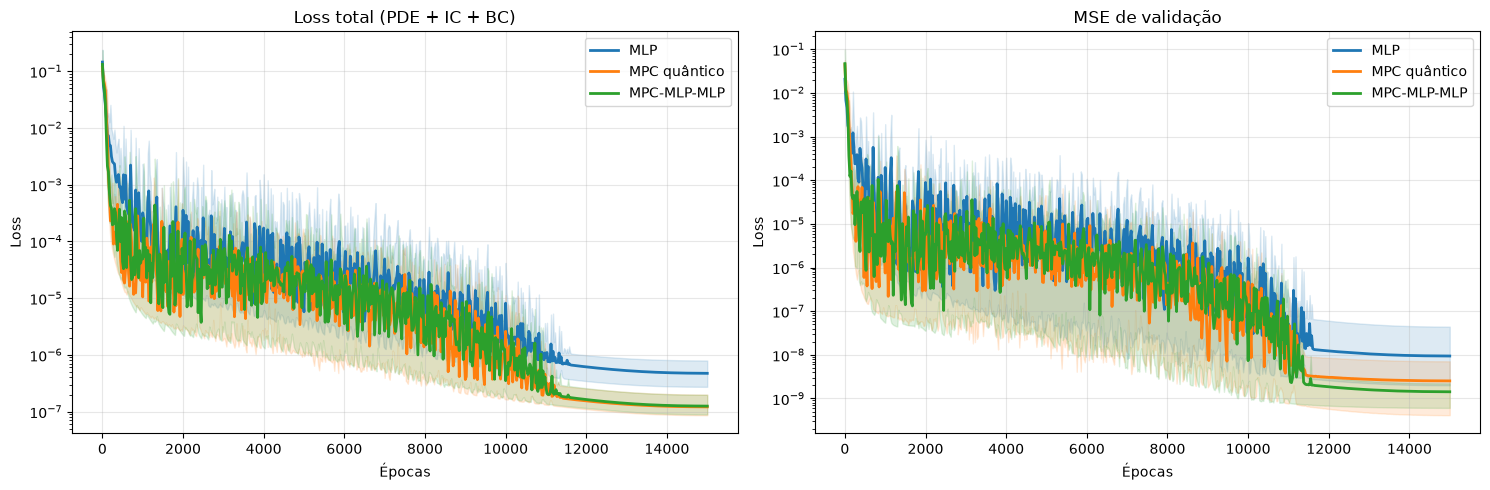

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, coluna, titulo in zip(
    axes,
    ["train_mse", "val_mse"],
    ["Loss total (PDE + IC + BC)", "MSE de validação"]
):

    for nome, h, m, cor in modelos:

        if h.empty:
            continue

        s = h.groupby("epoch")[coluna].agg(
            ["mean", "min", "max"]
        )

        ax.plot(
            s.index,
            s["mean"],
            color=cor,
            linewidth=2,
            label=nome
        )

        ax.fill_between(
            s.index,
            s["min"].to_numpy(),
            s["max"].to_numpy(),
            color=cor,
            alpha=0.15
        )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Loss")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Loss PDE, IC e BC

Identifica diferenças no ajuste das restrições físicas.

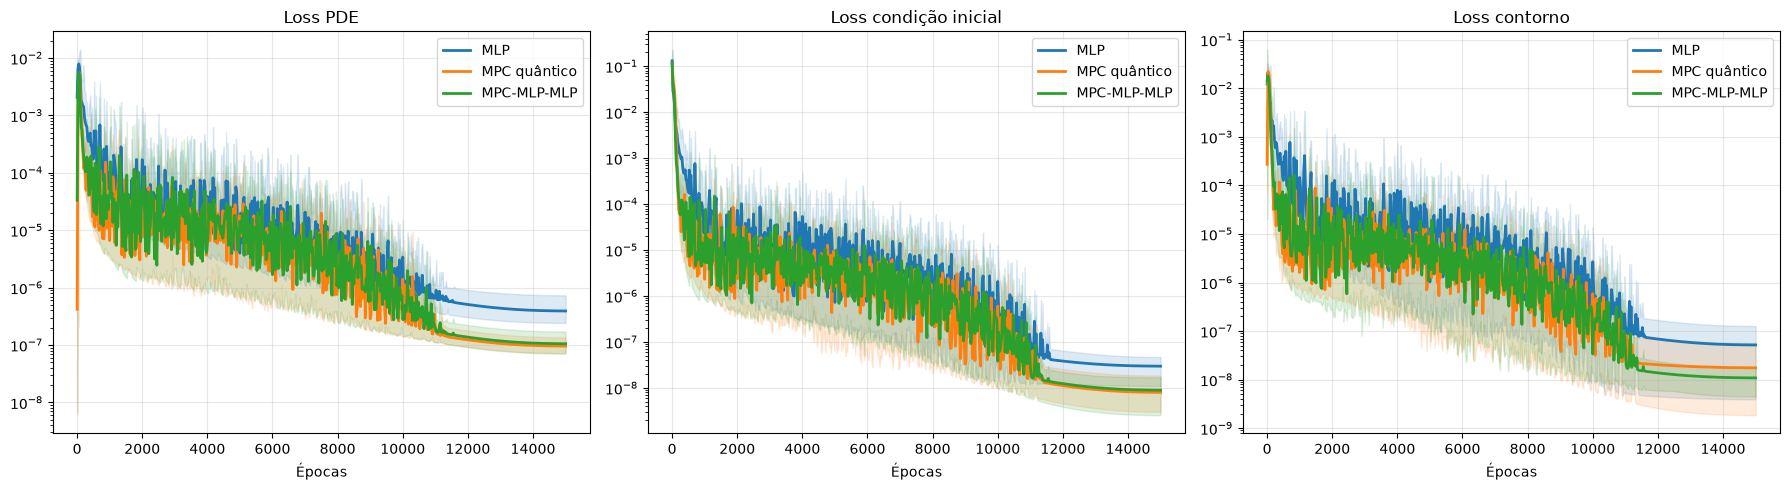

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

componentes = [
    ("loss_pde", "Loss PDE"),
    ("loss_ic", "Loss condição inicial"),
    ("loss_bc", "Loss contorno")
]

for ax, (coluna, titulo) in zip(axes, componentes):

    for nome, h, m, cor in modelos:

        if h.empty:
            continue

        s = h.groupby("epoch")[coluna].agg(
            ["mean", "min", "max"]
        )

        ax.plot(
            s.index,
            s["mean"],
            color=cor,
            linewidth=2,
            label=nome
        )

        ax.fill_between(
            s.index,
            s["min"].to_numpy(),
            s["max"].to_numpy(),
            color=cor,
            alpha=0.15
        )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Normas dos gradientes

Compara o bloco principal e os geradores de coeficientes.

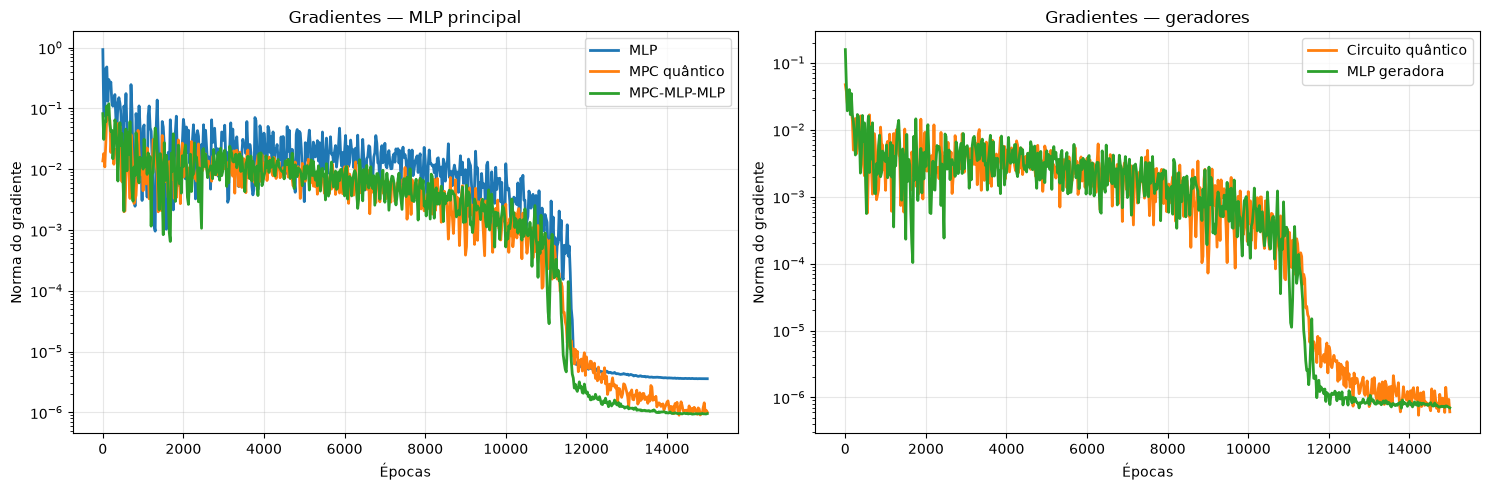

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gradientes da MLP principal
for nome, h, m, cor in modelos:

    if h.empty:
        continue

    s = h.groupby("epoch")["grad_classical"].mean()

    axes[0].plot(
        s.index, s.values,
        linewidth=2, color=cor, label=nome
    )

# Gradientes dos geradores
for h, coluna, nome, cor in [
    (hq_best, "grad_quantum", "Circuito quântico", "tab:orange"),
    (hc_best, "grad_generator", "MLP geradora", "tab:green")
]:

    if h.empty:
        continue

    s = h.groupby("epoch")[coluna].mean()

    axes[1].plot(
        s.index, s.values,
        linewidth=2, color=cor, label=nome
    )

for ax, titulo in zip(
    axes,
    ["Gradientes — MLP principal", "Gradientes — geradores"]
):
    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Norma do gradiente")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Boxplot final do RMSE de teste

Síntese do erro de inferência das três famílias.

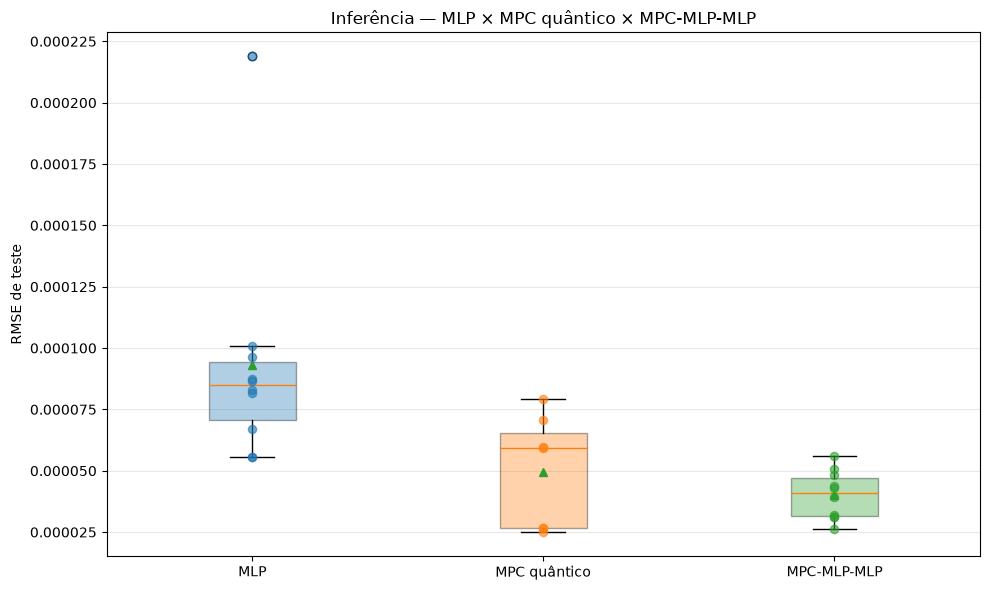

,Modelo,Sementes,RMSE médio,RMSE mínimo,RMSE máximo,Parâmetros
0,MLP,10,0.000093,0.000055,0.000219,3297
1,MPC quântico,7,0.000050,0.000025,0.000079,3459
2,MPC-MLP-MLP,10,0.000040,0.000026,0.000056,3455


In [ ]:
grupos = [
    m["rmse"].dropna().to_numpy()
    for nome, h, m, cor in modelos
]

nomes = [nome for nome, h, m, cor in modelos]
cores = [cor for nome, h, m, cor in modelos]

fig, ax = plt.subplots(figsize=(10, 6))

bp = ax.boxplot(
    grupos,
    tick_labels=nomes,
    showmeans=True,
    patch_artist=True
)

for patch, cor in zip(bp["boxes"], cores):
    patch.set_facecolor(cor)
    patch.set_alpha(0.35)

for i, (valores, cor) in enumerate(zip(grupos, cores), start=1):
    ax.scatter(
        np.full(len(valores), i),
        valores,
        color=cor,
        alpha=0.6,
        s=35,
        zorder=3
    )

ax.set_ylabel("RMSE de teste")
ax.set_title("Inferência — MLP × MPC quântico × MPC-MLP-MLP")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(pd.DataFrame([
    {
        "Modelo": nome,
        "Sementes": len(m),
        "RMSE médio": m["rmse"].mean(),
        "RMSE mínimo": m["rmse"].min(),
        "RMSE máximo": m["rmse"].max(),
        "Parâmetros": int(m["parameters"].iloc[0])
    }
    for nome, h, m, cor in modelos
]).round(6))

## 6. Apêndice — comparação exploratória MLP versus MPC 5q/3L

As células seguintes estavam no notebook original e foram preservadas como **análise exploratória anterior**, para não duplicar a comparação final na narrativa principal. Elas fazem uma seleção independente da melhor configuração quântica 5q/3L. **Execute-as separadamente**, pois reutilizam nomes de variáveis (`h_mlp`, `m_mlp`, `modelos`, `obs`) empregados na Seção 5.

### Seleção exploratória MLP × MPC

In [ ]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base = Path("/home/camaral/inct_cq_hybrid_nn/runs/pinn")

pasta_mlp = base / "mlp_depth_2706/results/burgers/pinn_mlp_depth_4"
pasta_mpc = base / "mpc_serial"


def carregar(arquivos):
    historicos, metricas = [], []

    for arquivo in arquivos:
        seed = int(arquivo.parent.name.split("_")[-1])

        with open(arquivo) as f:
            m = json.load(f)

        m["seed"] = seed
        metricas.append(m)

        h = arquivo.parent / "history.csv"

        if h.exists():
            d = pd.read_csv(h)
            d["seed"] = seed
            historicos.append(d)

    return (
        pd.concat(historicos, ignore_index=True)
        if historicos else pd.DataFrame(),
        pd.DataFrame(metricas)
    )


# MLP clássica
h_mlp, m_mlp = carregar(
    sorted(pasta_mlp.glob("seed_*/metrics.json"))
)

# MPC: pesquisar em todas as quatro etapas
arquivos_mpc = sorted(
    pasta_mpc.glob("0*_*/q5_l3_*/seed_*/metrics.json")
)

h_todos, m_todos = carregar(arquivos_mpc)

if m_todos.empty:
    print("Ainda não há treinamentos MPC 5q/3L concluídos.")

else:
    # Remover configurações repetidas
    m_todos = m_todos.drop_duplicates(
        ["observable", "coupling", "seed"]
    )

    ranking = (
        m_todos.groupby(["observable", "coupling"])["rmse"]
        .mean()
        .sort_values()
    )

    obs, coupling = ranking.index[0]

    # Selecionar apenas a melhor configuração
    arquivos = sorted(
        pasta_mpc.glob(
            f"0*_*/q5_l3_{obs}_{coupling}/seed_*/metrics.json"
        )
    )

    h_mpc, m_mpc = carregar(arquivos)

    h_mpc = h_mpc.drop_duplicates(["seed", "epoch"])
    m_mpc = m_mpc.drop_duplicates("seed")

    print(f"MPC selecionada: 5q / 3L / {obs.upper()} / {coupling}")
    print(f"MLP: {len(m_mlp)} sementes")
    print(f"MPC: {len(m_mpc)} sementes")

    if not m_mlp.empty:
        print(f"RMSE médio MLP: {m_mlp['rmse'].mean():.6e}")

    print(f"RMSE médio MPC: {m_mpc['rmse'].mean():.6e}")

    display(ranking)

MPC selecionada: 5q / 3L / XX / polynomial
MLP: 10 sementes
MPC: 7 sementes
RMSE médio MLP: 9.326027e-05
RMSE médio MPC: 4.959882e-05


observable  coupling  
xx          polynomial    0.000050
zz          polynomial    0.000057
z           polynomial    0.000066
Name: rmse, dtype: float64

### Loss total e validação

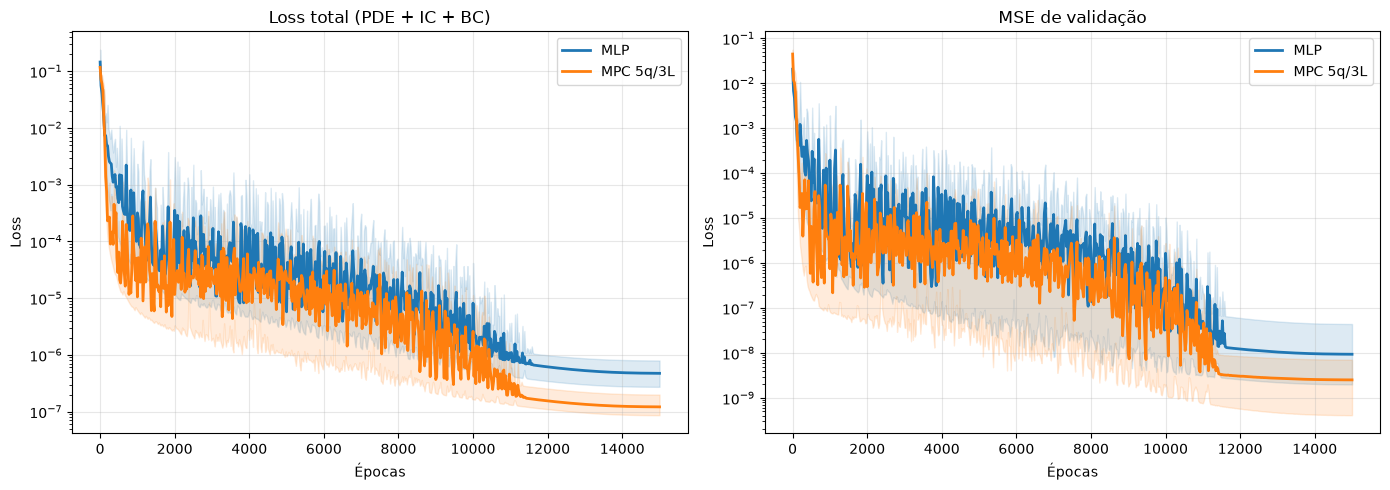

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

modelos = [
    (h_mlp, "MLP", "tab:blue"),
    (h_mpc, "MPC 5q/3L", "tab:orange")
]

for ax, coluna, titulo in zip(
    axes,
    ["train_mse", "val_mse"],
    ["Loss total (PDE + IC + BC)", "MSE de validação"]
):
    for h, nome, cor in modelos:

        s = h.groupby("epoch")[coluna].agg(["mean", "min", "max"])

        ax.plot(
            s.index, s["mean"],
            color=cor, linewidth=2, label=nome
        )

        ax.fill_between(
            s.index,
            s["min"].to_numpy(),
            s["max"].to_numpy(),
            color=cor, alpha=0.15
        )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Loss")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Loss PDE, IC e BC

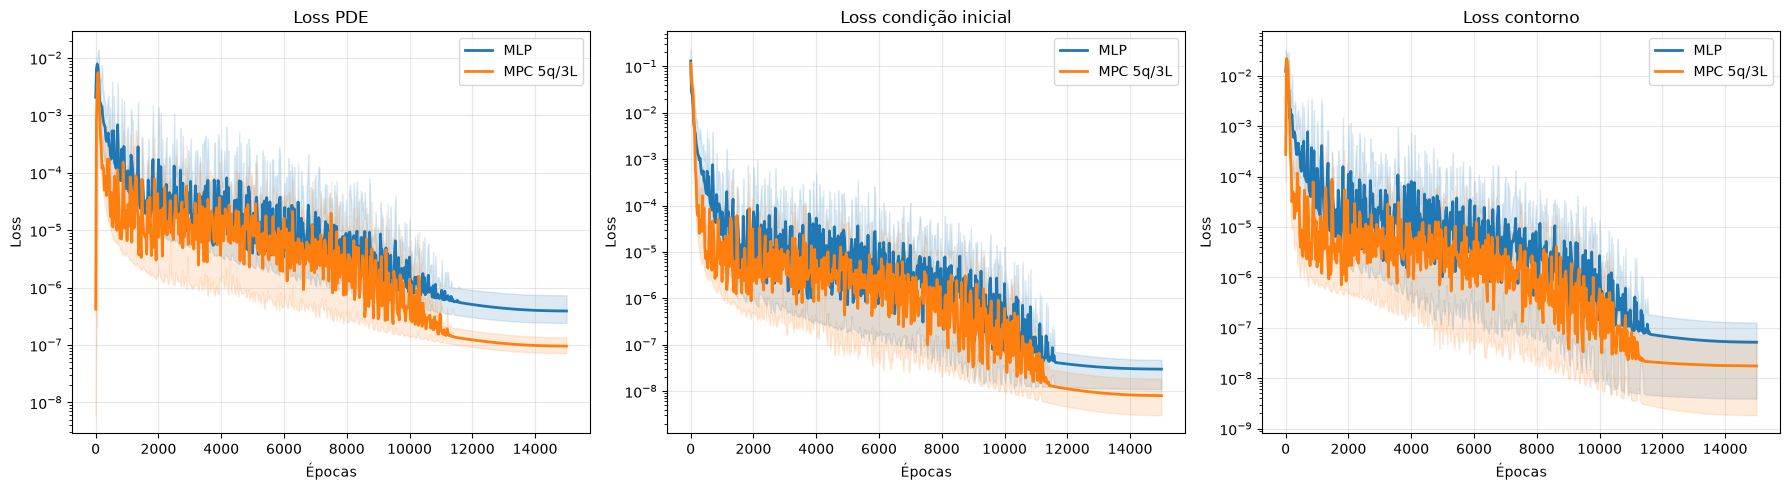

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

componentes = [
    ("loss_pde", "Loss PDE"),
    ("loss_ic", "Loss condição inicial"),
    ("loss_bc", "Loss contorno")
]

for ax, (coluna, titulo) in zip(axes, componentes):

    for h, nome, cor in modelos:

        s = h.groupby("epoch")[coluna].agg(["mean", "min", "max"])

        ax.plot(
            s.index, s["mean"],
            color=cor, linewidth=2, label=nome
        )

        ax.fill_between(
            s.index,
            s["min"].to_numpy(),
            s["max"].to_numpy(),
            color=cor, alpha=0.15
        )

    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Loss")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Gradientes clássicos e quânticos

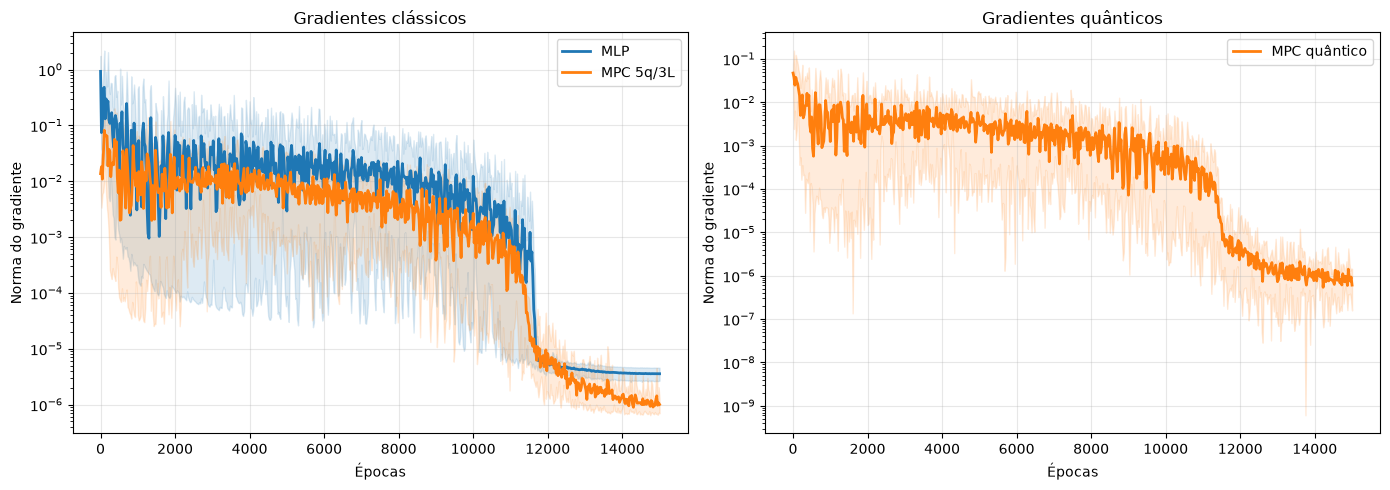

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gradientes clássicos
for h, nome, cor in modelos:

    s = h.groupby("epoch")["grad_classical"].agg(
        ["mean", "min", "max"]
    )

    axes[0].plot(
        s.index, s["mean"],
        color=cor, linewidth=2, label=nome
    )

    axes[0].fill_between(
        s.index,
        s["min"].to_numpy(),
        s["max"].to_numpy(),
        color=cor, alpha=0.15
    )

# Gradientes quânticos
s = h_mpc.groupby("epoch")["grad_quantum"].agg(
    ["mean", "min", "max"]
)

axes[1].plot(
    s.index, s["mean"],
    color="tab:orange", linewidth=2,
    label="MPC quântico"
)

axes[1].fill_between(
    s.index,
    s["min"].to_numpy(),
    s["max"].to_numpy(),
    color="tab:orange", alpha=0.15
)

for ax, titulo in zip(
    axes,
    ["Gradientes clássicos", "Gradientes quânticos"]
):
    ax.set_title(titulo)
    ax.set_xlabel("Épocas")
    ax.set_ylabel("Norma do gradiente")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Boxplot de teste

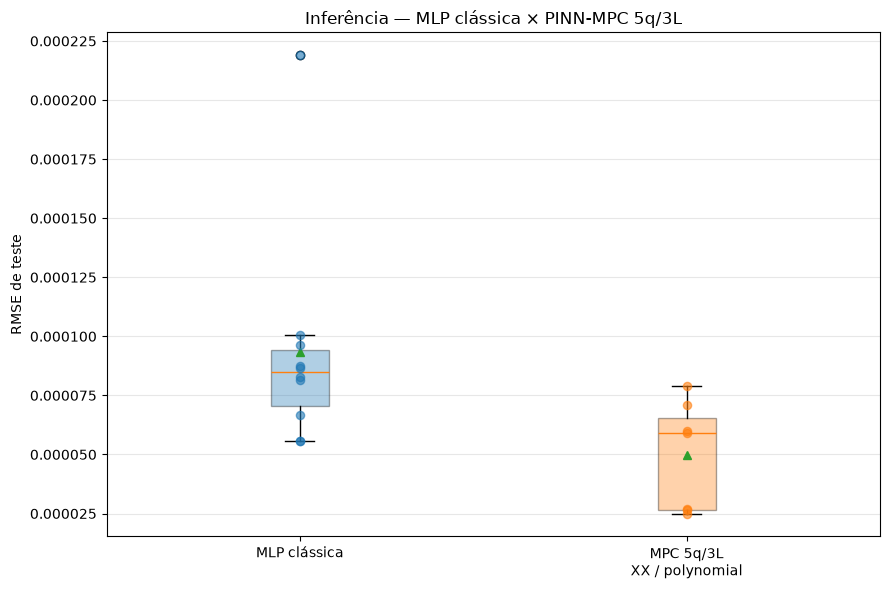

MLP — RMSE médio: 9.326027e-05
MPC — RMSE médio: 4.959882e-05
MLP — Parâmetros: 3297
MPC — Parâmetros: 3459


In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

grupos = [
    m_mlp["rmse"].dropna().to_numpy(),
    m_mpc["rmse"].dropna().to_numpy()
]

nomes = [
    "MLP clássica",
    f"MPC 5q/3L\n{obs.upper()} / {coupling}"
]

bp = ax.boxplot(
    grupos,
    tick_labels=nomes,
    showmeans=True,
    patch_artist=True
)

for patch, cor in zip(
    bp["boxes"], ["tab:blue", "tab:orange"]
):
    patch.set_facecolor(cor)
    patch.set_alpha(0.35)

for i, (valores, cor) in enumerate(
    zip(grupos, ["tab:blue", "tab:orange"]),
    start=1
):
    ax.scatter(
        np.full(len(valores), i),
        valores,
        color=cor,
        alpha=0.6,
        s=35,
        zorder=3
    )

ax.set_ylabel("RMSE de teste")
ax.set_title("Inferência — MLP clássica × PINN-MPC 5q/3L")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(f"MLP — RMSE médio: {np.mean(grupos[0]):.6e}")
print(f"MPC — RMSE médio: {np.mean(grupos[1]):.6e}")
print(f"MLP — Parâmetros: {int(m_mlp['parameters'].iloc[0])}")
print(f"MPC — Parâmetros: {int(m_mpc['parameters'].iloc[0])}")

---

### Notas sobre interpretação

- **Loss de treinamento** é física ($\mathcal{L}_{\mathrm{PDE}}+\mathcal{L}_{\mathrm{IC}}+\mathcal{L}_{\mathrm{BC}}$), enquanto **MSE de validação** compara as predições com a solução analítica.
- A comparação de parâmetros é especialmente informativa no **gerador de coeficientes**: o circuito quântico 5q/3L tem 30 parâmetros; as MLPs secundárias variam em torno desse valor.
- Para afirmar uma vantagem especificamente quântica, convém considerar a comparação equivalente por produto e a distribuição entre diferentes sementes, não apenas o menor RMSE isolado.
- Ao reexecutar, confira que os arquivos `metrics.json` e `history.csv` já foram gerados no servidor para as configurações que deseja comparar.